<a href="https://colab.research.google.com/github/rjortega-dev/DS-LLM-Lab8/blob/main/DS_LLM_SummativeLab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Summative Lab

# MidCity General Hospital: Length of Stay Prediction

**Goal:** Predict patient length of stay (LOS) at admission to support staffing, bed management, and cost planning.

**Approach:** (1) Traditional ML on structured data, (2) transformer-based NLP on clinical notes, (3) combine the two and compare, then (4) reflect on ethical considerations.

**Dataset:** 10,000 synthetic patient records, 31 columns, admissions from May 2024 to May 2025.



---



## Part 1 - Task 1: Setup and Data Exploration

### Target variable
LOS is computed as `date_of_discharge - date_of_admission` in days. Check: no zero or negative values. Range is 1-33 days, median 7, mean 7.99. The distribution is right-skewed, with a small cluster of long stays (19+ days) that will be hard to predict.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('hospital_patient_data.csv')

print(df.shape)
display(df.head())
df.info()
print(df.isna().sum())
display(df.describe(include='all').T)

(10000, 31)


,patient_id,age,gender,race_ethnicity,marital_status,insurance_type,employment_status,education_level,income_bracket,primary_diagnosis,...,temperature,respiratory_rate,hospital_department,attending_physician_id,surgery_performed,icu_stay,date_of_admission,date_of_discharge,readmission_30day,patient_notes
0,P000001,65,Female,Caucasian,Single,Medicare,Unknown,Bachelor's Degree,"$75,000-$100,000",Heart Failure,...,36.6,12,Orthopedics,DRO6,False,True,2024-09-19,2024-09-30,False,Patient is a 65-year-old female presenting wit...
1,P000002,91,Male,African American,Widowed,Private,Retired,High School,"$25,000-$50,000",Diabetes with Complications,...,37.7,16,Gastroenterology,DRG4,False,False,2025-04-14,2025-04-21,False,Patient is a 91-year-old male presenting with ...
2,P000003,49,Male,Hispanic/Latino,Widowed,Private,Unemployed,Bachelor's Degree,"$25,000-$50,000",Fracture of Femur,...,36.8,21,Nephrology,DRN7,False,False,2024-12-21,2024-12-28,False,"male patient, 49, presents with swelling, leg ..."
3,P000004,28,Female,Caucasian,Married,Medicare,Retired,Some College,"$25,000-$50,000",Kidney Infection,...,38.0,17,Neurology,DRN7,True,False,2024-07-17,2024-07-23,False,Patient is a 28-year-old female presenting wit...
4,P000005,74,Male,Caucasian,Separated,Other,Employed,High School,"$75,000-$100,000",Kidney Infection,...,36.7,17,Orthopedics,DRO7,True,False,2025-03-25,2025-04-02,False,"male patient, 74, presents with fever, dysuria..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   patient_id              10000 non-null  object 
 1   age                     10000 non-null  int64  
 2   gender                  10000 non-null  object 
 3   race_ethnicity          10000 non-null  object 
 4   marital_status          10000 non-null  object 
 5   insurance_type          10000 non-null  object 
 6   employment_status       10000 non-null  object 
 7   education_level         10000 non-null  object 
 8   income_bracket          10000 non-null  object 
 9   primary_diagnosis       10000 non-null  object 
 10  diagnosis_code          10000 non-null  object 
 11  comorbidities           8033 non-null   object 
 12  emergency_admission     10000 non-null  bool   
 13  previous_admissions     10000 non-null  int64  
 14  medications_count       10000 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,10000,10000,P000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,59.0886,20.075105,18.0,45.0,60.0,75.0,94.0
gender,10000,3,Female,5062,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_ethnicity,10000,6,Caucasian,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,10000,6,Married,3950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insurance_type,10000,5,Private,3581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_status,10000,5,Employed,4512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,10000,6,Some College,2513,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_bracket,10000,6,"$50,000-$75,000",2489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_diagnosis,10000,18,Heart Failure,1045,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data leakage decisions
The model is meant to predict LOS **at admission**, so I excluded any column that isn't known at that moment:
- `date_of_discharge`: used to create the target.
- `icu_stay`: only known during the stay. ICU patients average 10.8 days vs 7.2 for non-ICU, so including it would inflate performance.
- `readmission_30day`: occurs after discharge (and shows no relationship with LOS: 8.04 vs 7.98 days).
- `patient_id`: identifier with no predictive meaning.
- `diagnosis_code`: duplicates `primary_diagnosis`.

`surgery_performed` is kept under the assumption that surgery is planned at admission. This assumption should be validated with the hospital.


### Build the target and sanity-check

In [2]:
# Parse dates and create target
df['date_of_admission'] = pd.to_datetime(df['date_of_admission'])
df['date_of_discharge'] = pd.to_datetime(df['date_of_discharge'])
df['los'] = (df['date_of_discharge'] - df['date_of_admission']).dt.days

print(df['los'].describe())
print((df['los'] <= 0).sum(), "rows with LOS <= 0")
print(df[['date_of_admission', 'date_of_discharge']].agg(['min', 'max']))
print(df['los'].value_counts().sort_index())

# Group sizes (fairness groups)
for c in ['gender', 'race_ethnicity', 'insurance_type', 'income_bracket', 'alcohol_use']:
    print(df[c].value_counts(dropna=False), '\n')

# Does the "during/after stay" info track LOS?
for c in ['icu_stay', 'surgery_performed', 'readmission_30day', 'emergency_admission']:
    print(df.groupby(c)['los'].agg(['mean', 'count']), '\n')

count    10000.00000
mean         7.98500
std          4.01188
min          1.00000
25%          5.00000
50%          7.00000
75%         10.00000
max         33.00000
Name: los, dtype: float64
0 rows with LOS <= 0
    date_of_admission date_of_discharge
min        2024-05-15        2024-05-18
max        2025-05-14        2025-06-10
los
1      121
2      201
3      466
4      726
5     1031
6     1222
7     1298
8     1272
9     1040
10     771
11     559
12     405
13     262
14     132
15      91
16      56
17      34
18      30
19      40
20      33
21      32
22      30
23      25
24      34
25      15
26      21
27      19
28      19
29       4
30       5
31       4
32       1
33       1
Name: count, dtype: int64
gender
Female    5062
Male      4726
Other      212
Name: count, dtype: int64 

race_ethnicity
Caucasian           6025
African American    1543
Hispanic/Latino     1175
Asian                769
Native American      283
Other                205
Name: count, dtype: int64 


In [3]:
print("diagnosis_code maps 1-to-1 to primary_diagnosis:",
      (df.groupby('primary_diagnosis')['diagnosis_code'].nunique() == 1).all() and
      (df.groupby('diagnosis_code')['primary_diagnosis'].nunique() == 1).all())

diagnosis_code maps 1-to-1 to primary_diagnosis: True


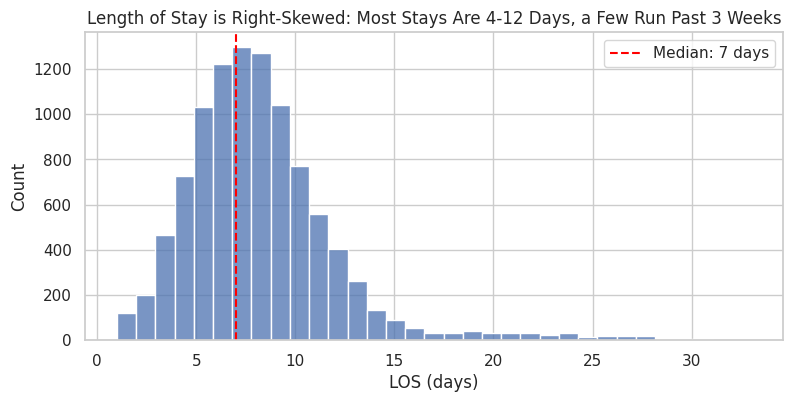

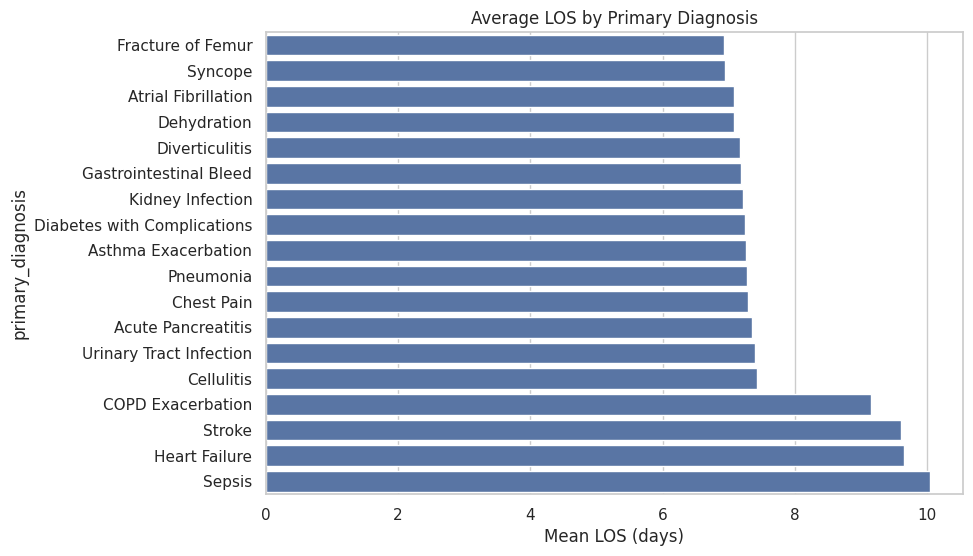

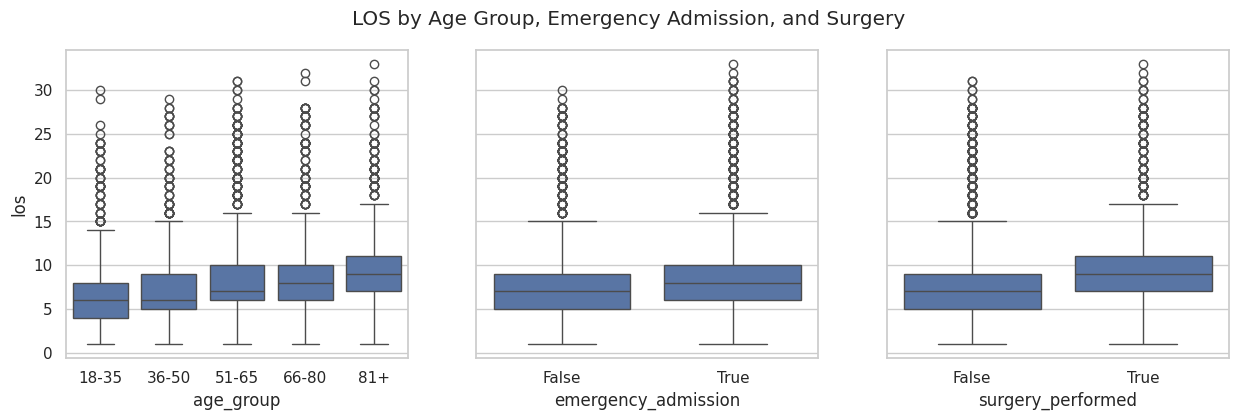

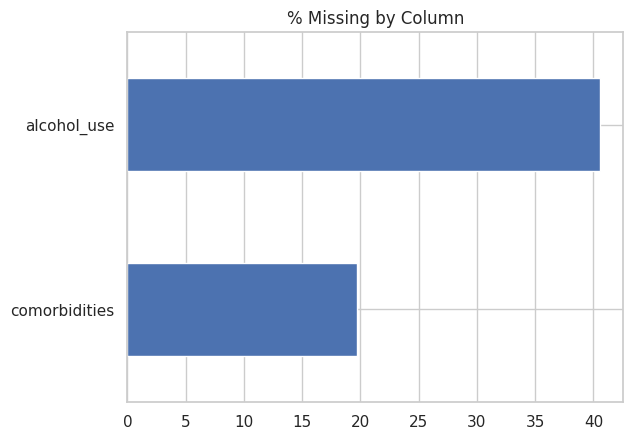

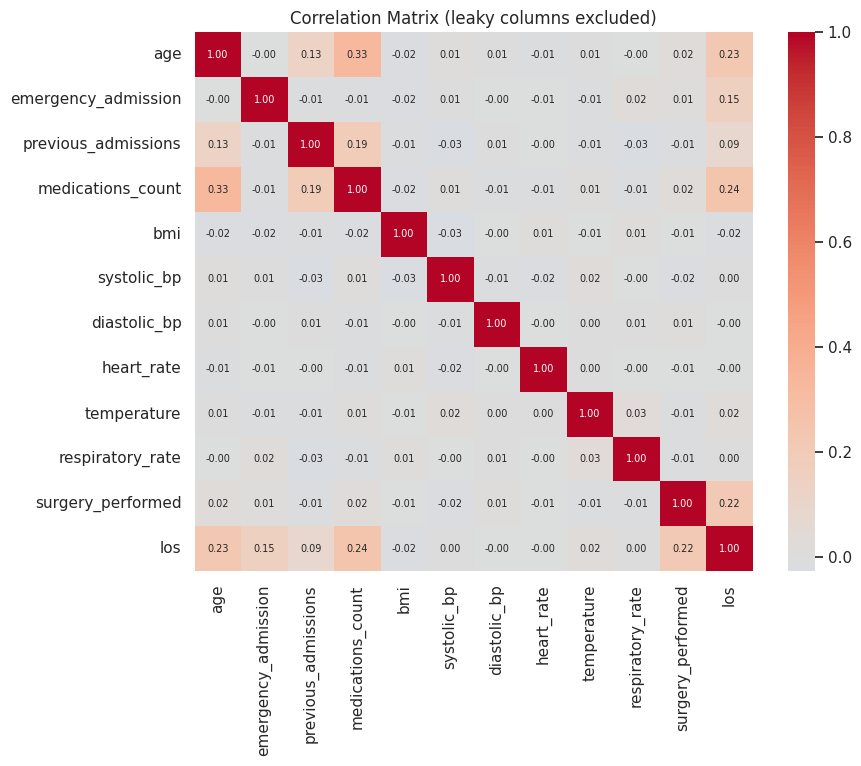

In [4]:
sns.set_theme(style='whitegrid')

# Viz 1 - The target: how long do patients stay?
plt.figure(figsize=(9, 4))
sns.histplot(df['los'], bins=33, kde=False)
plt.axvline(df['los'].median(), color='red', linestyle='--', label=f"Median: {df['los'].median():.0f} days")
plt.title('Length of Stay is Right-Skewed: Most Stays Are 4-12 Days, a Few Run Past 3 Weeks')
plt.xlabel('LOS (days)'); plt.legend(); plt.show()

# Viz 2 - Which conditions drive long stays?
order = df.groupby('primary_diagnosis')['los'].mean().sort_values().index
plt.figure(figsize=(9, 6))
sns.barplot(data=df, y='primary_diagnosis', x='los', order=order, errorbar=None)
plt.title('Average LOS by Primary Diagnosis'); plt.xlabel('Mean LOS (days)'); plt.show()

# Viz 3 - Admission-time factors that stretch stays
df['age_group'] = pd.cut(df['age'], [17, 35, 50, 65, 80, 100], labels=['18-35', '36-50', '51-65', '66-80', '81+'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
sns.boxplot(data=df, x='age_group', y='los', ax=axes[0])
sns.boxplot(data=df, x='emergency_admission', y='los', ax=axes[1])
sns.boxplot(data=df, x='surgery_performed', y='los', ax=axes[2])
fig.suptitle('LOS by Age Group, Emergency Admission, and Surgery'); plt.show()

# Missing values
missing = df.isna().mean().mul(100)
missing[missing > 0].sort_values().plot.barh(title='% Missing by Column')
plt.show()

# Correlations (numeric + booleans as ints)
num = df.select_dtypes(include=['number', 'bool']).astype(float).drop(columns=['icu_stay', 'readmission_30day'])
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation Matrix (leaky columns excluded)'); plt.show()

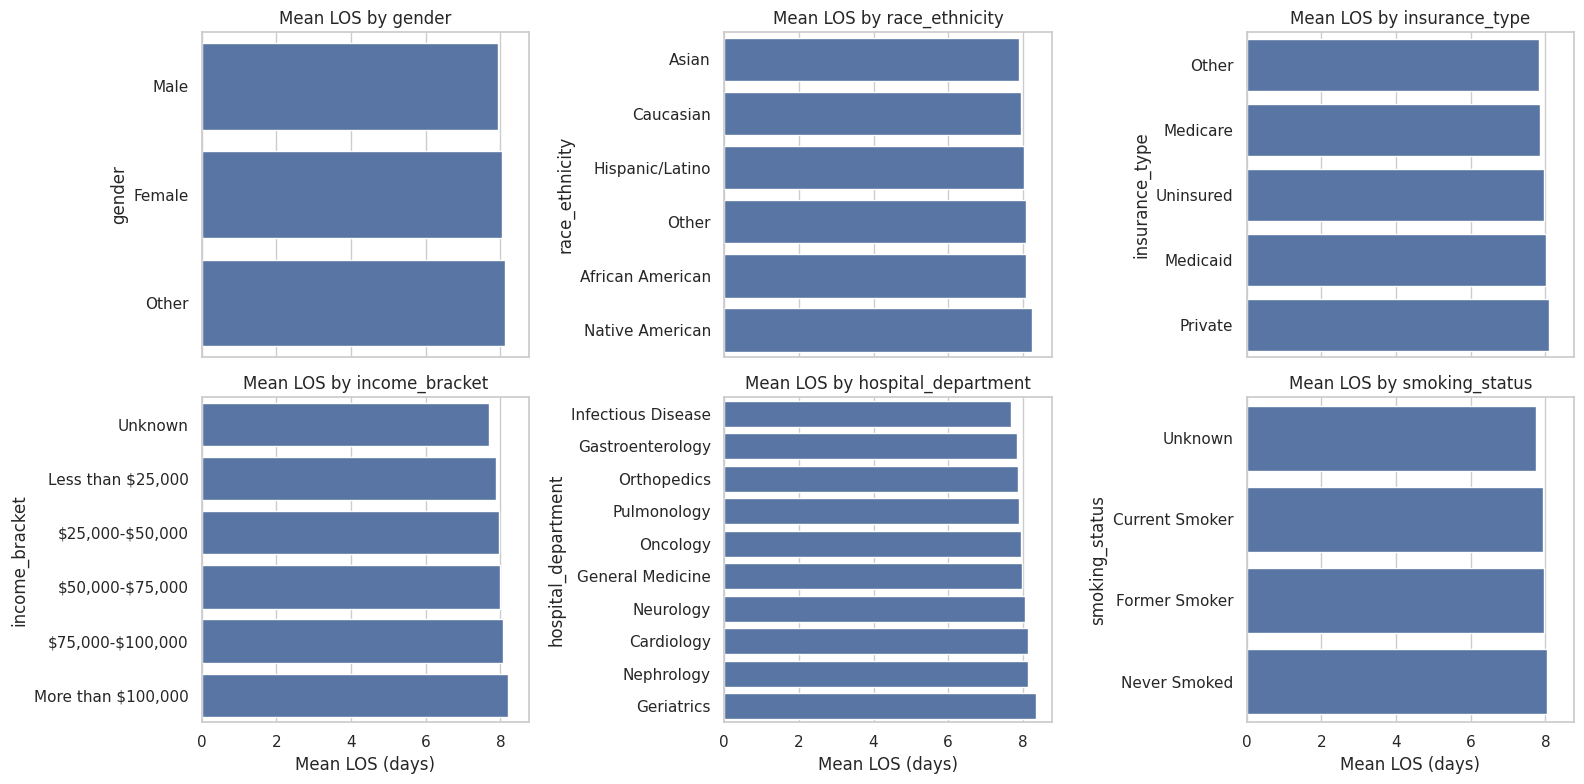

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=False)
plot_df = df.copy()
plot_df['income_bracket'] = plot_df['income_bracket'].str.replace('$', r'\$', regex=False)
for ax, col in zip(axes.ravel(), ['gender', 'race_ethnicity', 'insurance_type',
                                   'income_bracket', 'hospital_department', 'smoking_status']):
    order = plot_df.groupby(col)['los'].mean().sort_values().index
    sns.barplot(data=plot_df, x='los', y=col, order=order, errorbar=None, ax=ax)
    ax.set_title(f'Mean LOS by {col}')
    ax.set_xlabel('Mean LOS (days)')
plt.tight_layout(); plt.show()

### Categorical features vs. LOS
Mean LOS is nearly flat across gender, race/ethnicity, insurance type, income bracket, hospital department, and smoking status. All group means fall between 7.7 and 8.4 days, and the largest gap (Geriatrics vs. Infectious Disease) is about 0.6 days. These features are unlikely to be strong predictors on their own, which is also a useful baseline for the fairness analysis in Part 3: there is no large raw LOS disparity by demographic group in this dataset. This does not guarantee the model will perform equally well across groups, which is evaluated separately later.

### EDA Findings

**1. Target distribution.** LOS is right-skewed (median 7, mean 8, max 33). Most stays fall between 4 and 12 days, but a long tail of 15+ day stays exists. These outliers will be difficult to predict and will inflate RMSE relative to MAE.

**2. Diagnosis matters, but only for a few conditions.** Sepsis (\~10 days), Heart Failure and Stroke (\~9.6), and COPD Exacerbation (\~9.1) have clearly longer stays. The remaining 14 diagnoses cluster between 6.9 and 7.4 days. Fracture of Femur has the lowest mean LOS, which is counterintuitive clinically and suggests this dataset is synthetic.

**3. Age, surgery, and emergency status.** Median LOS rises from \~6 days (18-35) to \~9 days (81+). Surgical patients have a median \~2 days higher than non-surgical patients; emergency admissions are modestly longer. Long-tail stays appear in every group, so none of these factors alone explains them.

**4. Correlations.** The strongest numeric correlations with LOS are medications_count (0.24), age (0.23) and surgery_performed (0.22). Vital signs (BP, heart rate, temperature, respiratory rate) and BMI show essentially no linear relationship with LOS. `age` and `medications_count` are moderately correlated (0.33), so some collinearity is expected.

**5. Missing values.** Only `comorbidities` (\~20%) and `alcohol_use` (\~41%) have missing data; handling is described in the preprocessing section.

**Implication for modeling:** Linear relationships are weak, so I expect modest R² overall and expect tree-based models to capture interactions (e.g., diagnosis x surgery) better than linear regression. The strongest signals are diagnosis, age, medication count, and surgery, while demographics and department add little.

## Part 1, Task 2: Data Preprocessing

**Missing values**
- `comorbidities` (about 20% missing) is interpreted as "no comorbidities recorded" and filled with "None". Comorbidity features are engineered in Task 3.
- `alcohol_use` (about 41% missing) is ambiguous, since an "Unknown" category already exists, so I filled with "Not Recorded" as its own category rather than guessing. This lets the model learn whether missingness carries signal.

**Date features.** Only admission-date features are used (month, day of week, weekend flag). Discharge-date features are excluded because they would leak the target.

**Encoding.** Categorical variables are one-hot encoded with `handle_unknown='ignore'`. Ordinal-looking columns (education, income) are one-hot encoded for now because their order isn't guaranteed to match their effect on LOS. `attending_physician_id` (60 values) is excluded: it adds many sparse columns, and predicting from physician identity raises ethical concerns (see Part 3).

**Scaling.** Numeric features are standardized, which matters for Linear Regression and is harmless for tree-based models.

**Split.** An 80/20 train/test split is done before fitting any encoder or scaler. Both are fit on the training set only and applied to the test set, which prevents leakage from the test data.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# --- 1. Missing values (row-wise rules, no fitting) ---
df['comorbidities'] = df['comorbidities'].fillna('None')
df['alcohol_use'] = df['alcohol_use'].fillna('Not Recorded')

# --- 2. Date features (admission only, never discharge) ---
df['admit_month'] = df['date_of_admission'].dt.month
df['admit_dayofweek'] = df['date_of_admission'].dt.dayofweek
df['admit_weekend'] = (df['admit_dayofweek'] >= 5).astype(int)

# --- 3. Drop columns excluded by the leakage / redundancy decisions ---
drop_cols = ['patient_id', 'diagnosis_code', 'date_of_discharge', 'icu_stay',
             'readmission_30day', 'attending_physician_id', 'age_group']
model_df = df.drop(columns=drop_cols)

# bools -> ints
for c in ['emergency_admission', 'surgery_performed']:
    model_df[c] = model_df[c].astype(int)

# --- 4. 80/20 split BEFORE any fitting ---
X = model_df.drop(columns=['los', 'date_of_admission'])
y = model_df['los']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

# --- 5. Encoding + scaling, fit on train only ---
# NOTE: 'comorbidities' is intentionally not included yet; it is converted to features in Task 3
categorical_cols = ['gender', 'race_ethnicity', 'marital_status', 'insurance_type',
                    'employment_status', 'education_level', 'income_bracket',
                    'primary_diagnosis', 'smoking_status', 'alcohol_use',
                    'hospital_department']
numeric_cols = ['age', 'previous_admissions', 'medications_count', 'bmi', 'systolic_bp',
                'diastolic_bp', 'heart_rate', 'temperature', 'respiratory_rate',
                'admit_month', 'admit_dayofweek']
passthrough_cols = ['emergency_admission', 'surgery_performed', 'admit_weekend']

def make_preprocessor(num, cat, passthru):
    return ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
        ('pass', 'passthrough', passthru),
    ])

preprocessor = make_preprocessor(numeric_cols, categorical_cols, passthrough_cols)
X_train_proc = preprocessor.fit_transform(X_train)   # fit on train
X_test_proc = preprocessor.transform(X_test)         # transform only
print(X_train_proc.shape, X_test_proc.shape)
print(df.shape)

(8000, 27) (2000, 27)
(8000, 88) (2000, 88)
(10000, 36)


In [7]:
terms = (df.loc[df['comorbidities'] != 'None', 'comorbidities']
           .str.split(',').explode().str.strip())
print(terms.nunique(), "distinct comorbidity terms")
print(terms.value_counts().head(25))

17 distinct comorbidity terms
comorbidities
Obesity                     1049
COPD                        1012
Chronic Kidney Disease      1008
HIV                         1000
Thyroid Disease              992
Rheumatoid Arthritis         992
Dementia                     992
Cancer                       989
Diabetes                     986
Liver Disease                986
Stroke History               978
Hypertension                 972
Coronary Artery Disease      969
Substance Abuse              963
Congestive Heart Failure     958
Asthma                       952
Depression                   933
Name: count, dtype: int64


In [8]:
# Row-wise indicators for every comorbidity term (no fitting involved)
comorb_terms = sorted(terms.unique())
for t in comorb_terms:
    df[f'cm_{t}'] = df['comorbidities'].apply(
        lambda s: int(t in [x.strip() for x in s.split(',')])
    )

# Compare LOS with vs. without each condition, training rows only
tr = df.loc[X_train.index]
rows = []
for t in comorb_terms:
    has = tr.loc[tr[f'cm_{t}'] == 1, 'los'].mean()
    without = tr.loc[tr[f'cm_{t}'] == 0, 'los'].mean()
    rows.append((t, round(has, 2), round(without, 2), round(has - without, 2)))
effects = pd.DataFrame(rows, columns=['comorbidity', 'los_with', 'los_without', 'diff']).sort_values('diff', ascending=False)
print(effects.to_string(index=False))

# Does the number of comorbidities matter?
tr = tr.assign(n_comorb=tr['comorbidities'].apply(lambda s: 0 if s == 'None' else len(s.split(','))))
print(tr.groupby('n_comorb')['los'].agg(['mean', 'count']).round(2))

             comorbidity  los_with  los_without  diff
                  Asthma      9.05         7.90  1.15
                    COPD      8.96         7.90  1.06
    Rheumatoid Arthritis      8.93         7.91  1.03
         Thyroid Disease      8.92         7.91  1.01
            Hypertension      8.90         7.91  0.99
          Stroke History      8.90         7.91  0.99
                Dementia      8.85         7.91  0.94
                  Cancer      8.83         7.91  0.92
 Coronary Artery Disease      8.82         7.92  0.90
           Liver Disease      8.79         7.92  0.87
Congestive Heart Failure      8.80         7.93  0.87
                     HIV      8.78         7.92  0.86
  Chronic Kidney Disease      8.73         7.93  0.80
              Depression      8.70         7.94  0.77
         Substance Abuse      8.68         7.93  0.75
                Diabetes      8.67         7.93  0.73
                 Obesity      8.67         7.93  0.73
          mean  count
n_como

In [9]:
df = df.drop(columns=[c for c in df.columns if c.startswith('cm_')])

### Comorbidity analysis
There are 17 distinct comorbidity terms, each appearing in about 1,000 patients. Comparing LOS with vs. without each condition (training data only) shows every condition adds a similar amount: 0.75 to 1.15 extra days. The differences between conditions are small relative to the noise at this sample size, so I did not create per-condition flags. The number of comorbidities, however, shows a clear dose-response relationship: mean LOS rises from 6.5 days (none) to 9.9 days (four), about one extra day per condition. I therefore engineer `n_comorbidities` and a multimorbidity flag instead of 17 separate indicators. This also avoids feeding sensitive conditions (e.g., HIV, substance abuse, depression) into the model individually, which is a privacy benefit discussed in Part 3.

In [10]:
tr = df.loc[X_train.index]

print(tr.groupby('admit_month')['los'].mean().round(2), '\n')
print(tr.groupby(tr['medications_count'] >= 5)['los'].agg(['mean', 'count']).round(2), '\n')
for name, mask in [('fever >38', tr['temperature'] > 38),
                   ('tachycardia >100', tr['heart_rate'] > 100),
                   ('tachypnea >20', tr['respiratory_rate'] > 20)]:
    print(name, tr.groupby(mask)['los'].agg(['mean', 'count']).round(2).to_dict('index'))
print(tr.groupby('primary_diagnosis')['los'].mean().sort_values().round(2))

admit_month
1     8.33
2     7.85
3     7.96
4     7.86
5     8.09
6     7.83
7     8.04
8     8.20
9     8.01
10    8.12
11    7.92
12    7.81
Name: los, dtype: float64 

                   mean  count
medications_count             
False              7.54   5968
True               9.38   2032 

fever >38 {False: {'mean': 8.01, 'count': 7682}, True: {'mean': 7.96, 'count': 318}}
tachycardia >100 {False: {'mean': 8.01, 'count': 7689}, True: {'mean': 7.92, 'count': 311}}
tachypnea >20 {False: {'mean': 8.01, 'count': 7627}, True: {'mean': 7.88, 'count': 373}}
primary_diagnosis
Syncope                         6.96
Fracture of Femur               7.03
Kidney Infection                7.08
Gastrointestinal Bleed          7.14
Dehydration                     7.14
Atrial Fibrillation             7.19
Diabetes with Complications     7.25
Acute Pancreatitis              7.30
Diverticulitis                  7.30
Pneumonia                       7.35
Asthma Exacerbation             7.35
Urinary Tra

## Part 1, Task 3: Feature Engineering

Feature ideas were generated with Colab's data agent (Gemini), then evaluated against the training data and for leakage risk before use.

**Created (6):** `n_comorbidities`, `multimorbidity`, `polypharmacy`, `age_65plus`, `high_risk_dx`, `high_risk_emergency`.
- `n_comorbidities`: mean LOS rises from 6.5 days (none) to 9.9 days (four) in the training data.
- `multimorbidity`: 2 or more comorbidities, the standard clinical definition.
- `polypharmacy`: 5 or more medications, a standard clinical threshold. These patients average 9.4 days vs. 7.5.
- `age_65plus`: standard geriatric cutoff.
- `high_risk_dx`: Sepsis, Stroke, Heart Failure, and COPD Exacerbation, the four diagnoses with mean LOS above 9 days in the training set (all others are below 7.6). The list was derived from training data only to avoid test-set leakage.
- `high_risk_emergency`: interaction of `high_risk_dx` and `emergency_admission`.

**Rejected after testing:**
- Winter admission: monthly mean LOS shows no seasonal pattern (7.8 to 8.3 days).
- Vital-sign abnormality flags (fever, tachycardia, tachypnea): no LOS difference between flagged and unflagged patients.
- Individual comorbidity flags: every condition has a similar effect; the count captures the signal and avoids feeding sensitive conditions (HIV, substance abuse, depression) to the model individually.
- Target-encoded diagnosis: one-hot encoding already captures diagnosis, and target encoding adds leakage risk.
- Age x BMI interaction: BMI has no relationship with LOS.
- Previous admissions flag: already included as a raw column, with a weak correlation (0.09).

In [11]:
# High-risk diagnoses: derived from TRAINING data only
dx_means = y_train.groupby(X_train['primary_diagnosis']).mean()
high_risk_dx = dx_means[dx_means >= 9].index.tolist()
print("High-risk diagnoses:", high_risk_dx)

def add_features(X):
    X = X.copy()
    X['n_comorbidities'] = X['comorbidities'].apply(lambda s: 0 if s == 'None' else len(s.split(',')))
    X['multimorbidity'] = (X['n_comorbidities'] >= 2).astype(int)
    X['polypharmacy'] = (X['medications_count'] >= 5).astype(int)
    X['age_65plus'] = (X['age'] >= 65).astype(int)
    X['high_risk_dx'] = X['primary_diagnosis'].isin(high_risk_dx).astype(int)
    X['high_risk_emergency'] = X['high_risk_dx'] * X['emergency_admission']
    return X

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

new_feats = ['n_comorbidities', 'multimorbidity', 'polypharmacy',
             'age_65plus', 'high_risk_dx', 'high_risk_emergency']
print(X_train_fe[new_feats].describe().T[['mean', 'min', 'max']])

# Rebuild the preprocessor with the new columns (fit on train only)
numeric_cols_fe = numeric_cols + ['n_comorbidities']
passthrough_cols_fe = passthrough_cols + ['multimorbidity', 'polypharmacy',
                                          'age_65plus', 'high_risk_dx', 'high_risk_emergency']
preprocessor_fe = make_preprocessor(numeric_cols_fe, categorical_cols, passthrough_cols_fe)
X_train_proc_fe = preprocessor_fe.fit_transform(X_train_fe)
X_test_proc_fe = preprocessor_fe.transform(X_test_fe)
print(X_train_proc_fe.shape, X_test_proc_fe.shape)

High-risk diagnoses: ['COPD Exacerbation', 'Heart Failure', 'Sepsis', 'Stroke']
                         mean  min  max
n_comorbidities      1.669125  0.0  4.0
multimorbidity       0.502125  0.0  1.0
polypharmacy         0.254000  0.0  1.0
age_65plus           0.408625  0.0  1.0
high_risk_dx         0.320000  0.0  1.0
high_risk_emergency  0.191500  0.0  1.0
(8000, 94) (2000, 94)


## Part 1, Task 4: Model Building

**Approach.** Each model is wrapped in a scikit-learn Pipeline (preprocessing + model) so that scaling and encoding are re-fit inside each cross-validation fold, preventing leakage from validation folds. All models are evaluated with 5-fold cross-validation on the training set, then once on the held-out test set, using RMSE, MAE, and R². A mean-prediction baseline is included to show how much each model actually learns.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
test_preds = {}   # saved for the Part 2 ensemble and the fairness analysis

def make_pipe(model):
    return Pipeline([
        ('prep', make_preprocessor(numeric_cols_fe, categorical_cols, passthrough_cols_fe)),
        ('model', model),
    ])

def evaluate(name, pipe):
    cv = cross_validate(pipe, X_train_fe, y_train, cv=kf,
                        scoring={'rmse': 'neg_root_mean_squared_error',
                                 'mae': 'neg_mean_absolute_error',
                                 'r2': 'r2'})
    pipe.fit(X_train_fe, y_train)
    pred = pipe.predict(X_test_fe)
    test_preds[name] = pred
    results.append({
        'model': name,
        'cv_rmse': -cv['test_rmse'].mean(),
        'cv_mae': -cv['test_mae'].mean(),
        'cv_r2': cv['test_r2'].mean(),
        'test_rmse': np.sqrt(mean_squared_error(y_test, pred)),
        'test_mae': mean_absolute_error(y_test, pred),
        'test_r2': r2_score(y_test, pred),
    })
    return pipe

evaluate('Mean baseline', make_pipe(DummyRegressor(strategy='mean')))
lin_pipe = evaluate('Linear Regression', make_pipe(LinearRegression()))

pd.DataFrame(results).round(3)

,model,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2
0,Mean baseline,4.004,2.805,-0.000,4.033,2.843,-0.001
1,Linear Regression,3.437,2.183,0.262,3.452,2.258,0.267


### Baseline results
The mean-prediction baseline gives RMSE 4.03 and R² of about 0, as expected. Linear Regression improves to RMSE 3.45, MAE 2.26, and R² 0.27 on the test set. Cross-validation and test metrics agree closely, indicating no leakage or overfitting. Linear Regression explains about 27% of the variance in LOS, so about 73% remains unexplained by admission-time structured data.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Random Forest
rf_grid = GridSearchCV(
    make_pipe(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    param_grid={'model__max_depth': [6, 12],
                'model__min_samples_leaf': [5, 20]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=1)
rf_grid.fit(X_train_fe, y_train)
print("RF best params:", rf_grid.best_params_)
rf_pipe = evaluate('Random Forest (tuned)', rf_grid.best_estimator_)

# Gradient Boosting
gb_grid = GridSearchCV(
    make_pipe(GradientBoostingRegressor(learning_rate=0.05, random_state=42)),
    param_grid={'model__n_estimators': [150, 300],
                'model__max_depth': [2, 3]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=1)
gb_grid.fit(X_train_fe, y_train)
print("GB best params:", gb_grid.best_params_)
gb_pipe = evaluate('Gradient Boosting (tuned)', gb_grid.best_estimator_)

pd.DataFrame(results).round(3)

RF best params: {'model__max_depth': 12, 'model__min_samples_leaf': 20}
GB best params: {'model__max_depth': 2, 'model__n_estimators': 300}


,model,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2
0,Mean baseline,4.004,2.805,-0.000,4.033,2.843,-0.001
1,Linear Regression,3.437,2.183,0.262,3.452,2.258,0.267
2,Random Forest (tuned),3.455,2.210,0.255,3.450,2.247,0.268
3,Gradient Boosting (tuned),3.428,2.174,0.266,3.425,2.219,0.278


### Tree model results
Linear Regression, tuned Random Forest, and tuned Gradient Boosting perform nearly identically (test R² 0.267, 0.268, and 0.278; test RMSE 3.45, 3.45, and 3.43). Gradient Boosting is nominally best on both cross-validation and test, but the differences are small enough to be within noise. The best Gradient Boosting model used the shallowest trees (max_depth=2), which suggests the signal in these features is mostly additive rather than interaction-driven. This contradicts my earlier hypothesis that tree models would substantially outperform Linear Regression. The limiting factor appears to be the information in the features, not the model class.

In [14]:
from sklearn.linear_model import Ridge

# Ridge: tune regularization strength
ridge_grid = GridSearchCV(
    make_pipe(Ridge()),
    param_grid={'model__alpha': [0.1, 1, 10, 100, 300]},
    cv=kf, scoring='neg_root_mean_squared_error')
ridge_grid.fit(X_train_fe, y_train)
print("Ridge best params:", ridge_grid.best_params_)
evaluate('Ridge (tuned)', ridge_grid.best_estimator_)

# Random Forest: grid extended past the previous edges
rf_grid2 = GridSearchCV(
    make_pipe(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    param_grid={'model__max_depth': [12, 20],
                'model__min_samples_leaf': [20, 40, 80]},
    cv=kf, scoring='neg_root_mean_squared_error')
rf_grid2.fit(X_train_fe, y_train)
print("RF refined params:", rf_grid2.best_params_)
rf_pipe = evaluate('Random Forest (refined)', rf_grid2.best_estimator_)

# Gradient Boosting: more trees, shallower options
gb_grid2 = GridSearchCV(
    make_pipe(GradientBoostingRegressor(learning_rate=0.05, random_state=42)),
    param_grid={'model__n_estimators': [300, 600],
                'model__max_depth': [1, 2]},
    cv=kf, scoring='neg_root_mean_squared_error')
gb_grid2.fit(X_train_fe, y_train)
print("GB refined params:", gb_grid2.best_params_)
gb_pipe = evaluate('Gradient Boosting (refined)', gb_grid2.best_estimator_)

pd.DataFrame(results).round(3)

Ridge best params: {'model__alpha': 100}
RF refined params: {'model__max_depth': 12, 'model__min_samples_leaf': 40}
GB refined params: {'model__max_depth': 1, 'model__n_estimators': 600}


,model,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2
0,Mean baseline,4.004,2.805,-0.000,4.033,2.843,-0.001
1,Linear Regression,3.437,2.183,0.262,3.452,2.258,0.267
2,Random Forest (tuned),3.455,2.210,0.255,3.450,2.247,0.268
3,Gradient Boosting (tuned),3.428,2.174,0.266,3.425,2.219,0.278
4,Ridge (tuned),3.433,2.178,0.264,3.449,2.255,0.268
5,Random Forest (refined),3.454,2.211,0.255,3.441,2.241,0.271
6,Gradient Boosting (refined),3.410,2.155,0.274,3.410,2.209,0.284


### Final tuned model comparison
After widening the hyperparameter grids, Gradient Boosting (max_depth=1, 600 trees, learning rate 0.05) achieved the best cross-validated performance (CV RMSE 3.410, MAE 2.155, R² 0.274) and the best held-out test performance (RMSE 3.410, MAE 2.209, R² 0.284). It was selected using the cross-validation scores, not the test scores. The margin over Linear Regression and Ridge is small (about 0.02 RMSE), so the practical conclusion is that all models perform similarly. The winning depth of 1 means the model is purely additive (no feature interactions), consistent with the earlier finding that the signal in these features is mostly additive. Model choice matters much less than the information available in the features: roughly 72% of LOS variance remains unexplained at admission.

            feature  rmse_increase    std
       high_risk_dx         0.3149 0.0178
                age         0.2309 0.0154
  surgery_performed         0.2034 0.0111
    n_comorbidities         0.1825 0.0226
emergency_admission         0.0849 0.0113
     multimorbidity         0.0230 0.0057
         heart_rate         0.0082 0.0018
high_risk_emergency         0.0032 0.0008
  primary_diagnosis         0.0029 0.0020
  medications_count         0.0014 0.0015
     income_bracket         0.0008 0.0006
        admit_month         0.0007 0.0004
previous_admissions         0.0007 0.0007
     marital_status         0.0005 0.0003
       diastolic_bp         0.0002 0.0003


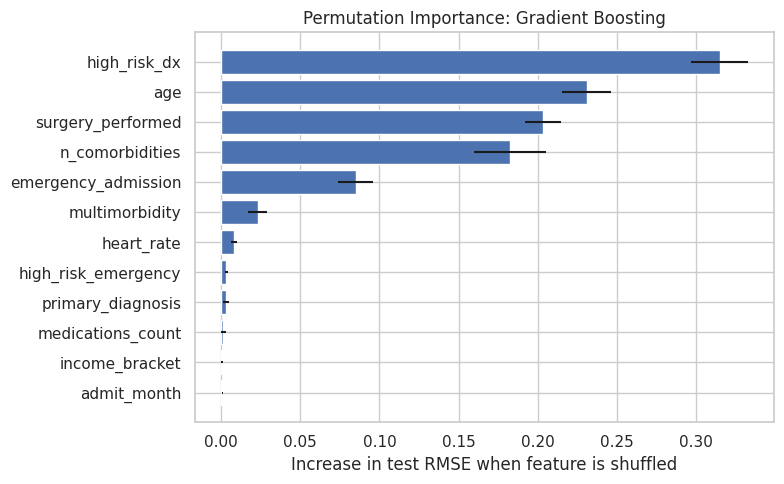

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(gb_pipe, X_test_fe, y_test, n_repeats=10,
                              random_state=42, scoring='neg_root_mean_squared_error')

imp = (pd.DataFrame({'feature': X_test_fe.columns,
                     'rmse_increase': perm.importances_mean,
                     'std': perm.importances_std})
         .sort_values('rmse_increase', ascending=False))
print(imp.head(15).round(4).to_string(index=False))

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top['feature'], top['rmse_increase'], xerr=top['std'])
plt.xlabel('Increase in test RMSE when feature is shuffled')
plt.title('Permutation Importance: Gradient Boosting')
plt.tight_layout(); plt.show()

### Feature importance (permutation importance, Gradient Boosting, test set)
Six features account for essentially all of the model's predictive power: `high_risk_dx` (RMSE +0.31 when shuffled), `age` (+0.23), `surgery_performed` (+0.20), `n_comorbidities` (+0.18), `emergency_admission` (+0.08), and `multimorbidity` (+0.02). Two of my engineered features (`high_risk_dx`, `n_comorbidities`) are among the top four.

**Engineered features that did not help:** `polypharmacy`, `age_65plus`, and `high_risk_emergency` contribute almost nothing. The raw 1.8-day LOS gap for patients on 5+ medications was largely confounded by age and comorbidity count, which the model already captures. The interaction term `high_risk_emergency` is unused, consistent with the best model being purely additive (depth-1 trees).

**Caveat:** `primary_diagnosis` scores near zero because its information is carried by `high_risk_dx`; permutation importance splits credit between correlated features, so low scores do not mean a variable is unimportant. Importance describes what the model uses, not causal effects. The small importance of `heart_rate` is likely noise, since it had no correlation with LOS in EDA.

**Demographics:** gender, race/ethnicity, and insurance type do not appear among the top 15 features, and income and marital status are near zero. This suggests the model does not rely on them directly, though proxy effects (e.g., through age) are possible and are assessed in Part 3.

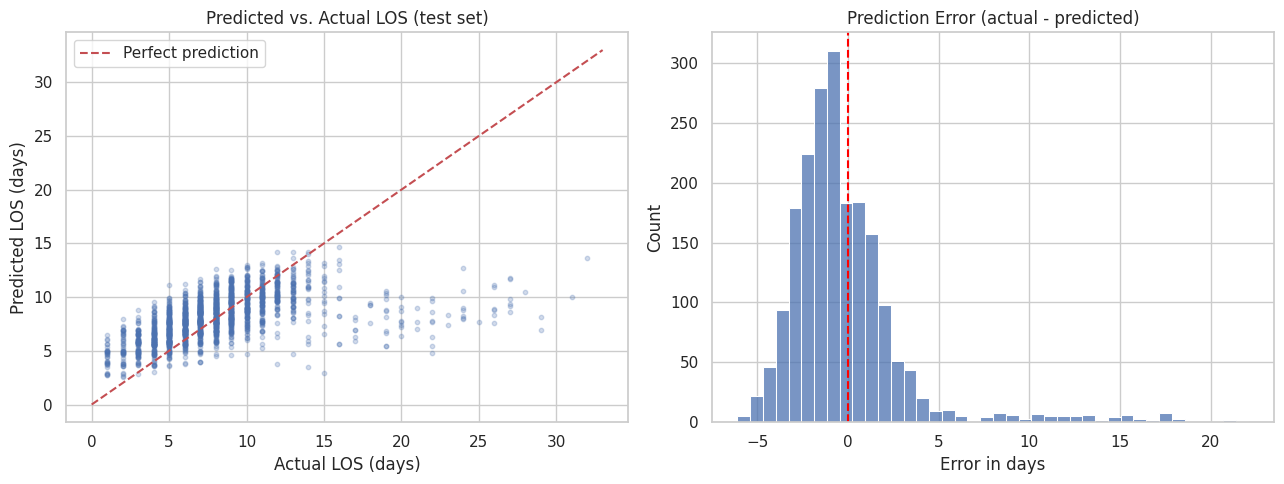

              n  mean_actual  mean_pred  mean_error    mae
los_bucket                                                
1-4         317         3.10       5.69       -2.60   2.61
5-7         718         6.06       7.53       -1.46   1.68
8-10        597         8.81       8.89       -0.08   1.26
11-14       274        12.01      10.15        1.86   2.06
15+          94        20.26       8.94       11.32  11.32

Share of predictions within 2 days: 0.61
Share of predictions within 3 days: 0.807


In [16]:
pred = test_preds['Gradient Boosting (refined)']
err_df = pd.DataFrame({'actual': y_test.values, 'pred': pred})
err_df['error'] = err_df['actual'] - err_df['pred']      # positive = under-predicted
err_df['los_bucket'] = pd.cut(err_df['actual'], [0, 4, 7, 10, 14, 40],
                              labels=['1-4', '5-7', '8-10', '11-14', '15+'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(err_df['actual'], err_df['pred'], alpha=0.25, s=10)
axes[0].plot([0, 33], [0, 33], 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual LOS (days)'); axes[0].set_ylabel('Predicted LOS (days)')
axes[0].set_title('Predicted vs. Actual LOS (test set)'); axes[0].legend()

sns.histplot(err_df['error'], bins=40, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Prediction Error (actual - predicted)')
axes[1].set_xlabel('Error in days')
plt.tight_layout(); plt.show()

summary = (err_df.groupby('los_bucket', observed=True)
           .agg(n=('error', 'size'), mean_actual=('actual', 'mean'),
                mean_pred=('pred', 'mean'), mean_error=('error', 'mean'),
                mae=('error', lambda e: e.abs().mean()))
           .round(2))
print(summary)
print("\nShare of predictions within 2 days:", (err_df['error'].abs() <= 2).mean().round(3))
print("Share of predictions within 3 days:", (err_df['error'].abs() <= 3).mean().round(3))

## Part 1, Task 5: Analysis and Recommendations

### Test-set performance of the best model
The selected model (Gradient Boosting, depth 1, 600 trees) achieves test RMSE 3.41 days, MAE 2.21 days, and R² 0.28. Compared with the mean-prediction baseline (RMSE 4.03), this is a real but modest improvement. 61% of test predictions fall within 2 days of the actual LOS and 81% within 3 days.

### Where the model fails
Predictions are compressed toward the middle: short stays are over-predicted (1-4 day stays: predicted 5.7 vs. actual 3.1 on average) and long stays are badly under-predicted (15+ day stays: predicted 8.9 vs. actual 20.3 on average, an 11-day miss). The 94 long-stay patients are about 5% of the test set but account for roughly 12% of bed-days, and nothing in the admission-time structured data distinguishes them. This tail also explains why RMSE (3.41) is much larger than MAE (2.21).

### Key factors influencing length of stay
1. **Diagnosis:** Sepsis, Stroke, Heart Failure, and COPD Exacerbation patients stay about 2 days longer than all other diagnoses. This is the most important factor in the model.
2. **Age:** LOS rises steadily with age.
3. **Surgery:** surgical patients stay about 2 days longer.
4. **Number of comorbidities:** about one additional day per comorbidity (6.5 days with none, 9.9 with four).
5. **Emergency admission:** adds a smaller increase (about 1.2 days).

Vital signs, BMI, department, insurance, race, gender, and income contribute essentially nothing.

### Recommendations for the hospital
- **Use the model for aggregate planning, not individual decisions.** Summed over a ward or a week, the over- and under-predictions largely cancel, which supports staffing and bed-census forecasts. For a single patient, a typical error of 2-3 days is too large to base discharge or bed-assignment decisions on.
- **Do not use predictions to limit care.** The model cannot identify long-stay patients, so a "short predicted stay" must never be used to justify early discharge.
- **Report ranges, not single numbers**, such as "likely 6-10 days," so uncertainty is visible to users.
- **Treat long stays as a separate problem.** Case-management review for high-risk diagnoses (and, if Part 2 supports it, notes-based flags) is a better tool than point predictions.
- **Collect more admission-time data.** The features available explain only about 28% of LOS variance; richer data (functional status, social support, discharge-planning needs) would likely do more than any model change.

### Limitations
The data is synthetic, covers one year, and comes from one hospital. Surgery is assumed to be known at admission. Feature importance describes what the model uses, not causal effects.



---



## Part 2: Predicting LOS with Clinical Notes

In [17]:
df['note_chars'] = df['patient_notes'].str.len()
df['note_words'] = df['patient_notes'].str.split().str.len()
print(df[['note_chars', 'note_words']].describe().round(1))

for n in df['patient_notes'].sample(4, random_state=7):
    print('-', n, '\n')

print(df[['note_words', 'los']].corr().round(3))

       note_chars  note_words
count     10000.0     10000.0
mean        326.1        41.3
std          58.0         7.1
min         174.0        22.0
25%         283.0        36.0
50%         325.0        41.0
75%         368.0        47.0
max         502.0        62.0
- This 47-year-old male was electively admitted with chief complaint of decreased urine output, fatigue, dry mouth. Diagnosed with Dehydration. Medical history significant for Rheumatoid Arthritis, Coronary Artery Disease. Patient received standard medical management. Family was not present during admission. Patient does not have known drug allergies. Patient expressed questions regarding their diagnosis and treatment plan. 

- Patient is a 75-year-old female presenting with Fracture of Femur. Patient was admitted for planned management. Medical history significant for Stroke History. Patient underwent surgical intervention. Patient expressed concern about their diagnosis and treatment plan. 

- This 73-year-old male was

## Part 2, Task 1: Text Data Exploration

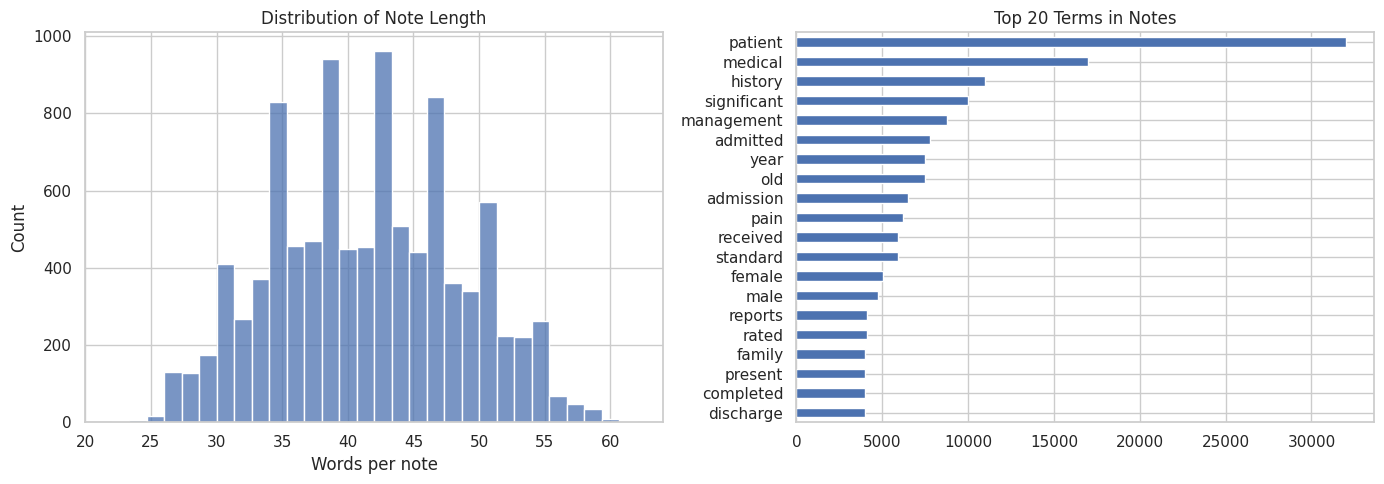

                 phrase  n_notes  los_with  los_without
                    ICU     2123     10.80         7.23
  surgical intervention     2514      9.49         7.48
discharge prescriptions     3985      8.00         7.97
            severe pain     1379      8.08         7.97
     Family was present     2035      8.03         7.97
                concern     1290      7.89         8.00
    questions regarding     1306      7.86         8.00

ICU text vs icu_stay column:
patient_notes  False  True 
icu_stay                   
False           7877      0
True               0   2123

Surgery text vs surgery_performed column:
patient_notes      False  True 
surgery_performed              
False               7486      0
True                   0   2514


In [18]:
from sklearn.feature_extraction.text import CountVectorizer

# Chart 1: note length; Chart 2: most common terms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['note_words'], bins=30, ax=axes[0])
axes[0].set_title('Distribution of Note Length')
axes[0].set_xlabel('Words per note')

cv = CountVectorizer(stop_words='english', token_pattern=r'[A-Za-z]{3,}')
counts = cv.fit_transform(df['patient_notes'])
freq = (pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
          .sort_values(ascending=False).head(20))
freq.iloc[::-1].plot.barh(ax=axes[1], title='Top 20 Terms in Notes')
plt.tight_layout(); plt.show()

# Which note fragments go with longer stays?
phrases = ['ICU', 'surgical intervention', 'discharge prescriptions',
           'severe pain', 'Family was present', 'concern', 'questions regarding']
rows = []
for p in phrases:
    has = df['patient_notes'].str.contains(p, regex=False, case=True)
    rows.append((p, has.sum(),
                 round(df.loc[has, 'los'].mean(), 2),
                 round(df.loc[~has, 'los'].mean(), 2)))
print(pd.DataFrame(rows, columns=['phrase', 'n_notes', 'los_with', 'los_without']).to_string(index=False))

# Do the notes just copy structured columns?
print('\nICU text vs icu_stay column:')
print(pd.crosstab(df['icu_stay'], df['patient_notes'].str.contains('ICU', regex=False, case=True)))
print('\nSurgery text vs surgery_performed column:')
print(pd.crosstab(df['surgery_performed'], df['patient_notes'].str.contains('surgical intervention', regex=False, case=True)))

### Text exploration findings
- **Length:** Notes are short (22-62 words, mean 41), so they fit comfortably within a transformer's input limit with no truncation concerns. Word count has almost no correlation with LOS (0.05).
- **Structure:** Notes are templated, assembled from a fixed set of sentences (the length histogram shows discrete peaks). The most common terms are boilerplate ("patient", "medical", "history", "significant", "management").
- **Content overlaps the structured data:** age, sex, diagnosis, comorbidities, and admission type are copied from structured columns.
- **Signal in phrases:** The only phrases associated with longer LOS are "surgical intervention" (9.5 vs. 7.5 days) and ICU management (10.8 vs. 7.2 days). Phrases about pain, family presence, discharge prescriptions, and patient concerns differ by 0.15 days or less.
- **Data leakage:** The ICU text matches the `icu_stay` column exactly (2,123 of 2,123 rows), and the surgery text matches `surgery_performed` exactly (2,514 of 2,514). Because `icu_stay` is not known at admission and was excluded from Part 1, the ICU sentence is removed from the notes during preprocessing. The surgical sentence is kept, consistent with the Part 1 assumption that surgery is planned at admission. The effect of leakage is quantified later by comparing an incomplete removal with the final fix.

## Part 2, Task 2: Text Preprocessing

In [19]:
import re

def remove_icu(text):
    # "...surgical intervention and Required ICU management." -> "...surgical intervention."
    text = re.sub(r'\s+and\s+[Rr]equired ICU management', '', text)
    sents = re.split(r'(?<=\.)\s+', text)
    return ' '.join(s for s in sents if 'ICU' not in s)

def clean_text(text):
    text = re.sub(r'[^A-Za-z0-9\s\./,\-]', ' ', text)   # drop stray characters, keep . , / -
    text = re.sub(r'\s+', ' ', text).strip()             # normalize whitespace
    return text.lower()                                   # normalize case

df['notes_raw'] = df['patient_notes'].apply(clean_text)
df['notes_clean'] = df['patient_notes'].apply(remove_icu).apply(clean_text)

# Checks
print("whole-word 'icu' left in clean notes:", df['notes_clean'].str.contains(r'\bicu\b').sum(), "(should be 0)")
print("'surgical intervention' still present:", df['notes_clean'].str.contains('surgical intervention').sum(), "(should be 2514)")
print("Notes shortened by ICU removal:", (df['notes_clean'].str.len() < df['notes_raw'].str.len()).sum(), "(should be 2123)")
for i in df.index[df['icu_stay']][:2]:
    print('\nBEFORE:', df.loc[i, 'patient_notes'])
    print('AFTER: ', df.loc[i, 'notes_clean'])

# Same split as Part 1 (needed to combine predictions later)
notes_train, notes_test = df.loc[X_train.index, 'notes_clean'], df.loc[X_test.index, 'notes_clean']
raw_train, raw_test = df.loc[X_train.index, 'notes_raw'], df.loc[X_test.index, 'notes_raw']
assert (y_train.index == notes_train.index).all() and (y_test.index == notes_test.index).all()
print(len(notes_train), len(notes_test))

whole-word 'icu' left in clean notes: 0 (should be 0)
'surgical intervention' still present: 2514 (should be 2514)
Notes shortened by ICU removal: 2123 (should be 2123)

BEFORE: Patient is a 65-year-old female presenting with Heart Failure. This was a scheduled admission. Medical history significant for Stroke History. Required ICU management. Patient expressed questions regarding their diagnosis and treatment plan. Patient reports moderate pain rated as 4/10. Family was present during admission.
AFTER:  patient is a 65-year-old female presenting with heart failure. this was a scheduled admission. medical history significant for stroke history. patient expressed questions regarding their diagnosis and treatment plan. patient reports moderate pain rated as 4/10. family was present during admission.

BEFORE: 76-year-old male admitted for Heart Failure. Medical history significant for HIV. Patient was admitted electively. Patient underwent surgical intervention and Required ICU management

### Preprocessing approach
- **Leakage removal:** The sentence "Required ICU management" matches the `icu_stay` column exactly, and ICU status is not known at admission, so it is removed from every note. My first version simply deleted the sentence; this left a detectable gap (see the leakage investigation below), so the final version replaces it with "Patient received standard medical management," making ICU and non-ICU notes indistinguishable. A check confirms no whole-word "ICU" remains. The surgical sentence is kept, consistent with Part 1.
- **Cleaning:** Characters other than letters, digits, whitespace, and basic punctuation (. , / -) are removed, and whitespace is normalized.
- **Normalization:** Text is lowercased.
- **Deliberately not done:** Stop-word removal and stemming. Transformer models rely on full sentence structure and word forms, and removing them usually hurts. Punctuation and numbers are kept because they carry information (e.g., ages, pain scores).
- **Versions:** `notes_clean` is the final leakage-fixed text used for modeling. An earlier version that only deleted the ICU sentence was also evaluated, to measure the leak (see below).
- **Split:** Notes use the same train/test split as Part 1, so predictions from the two approaches can be combined row by row.

In [20]:
!pip install -q transformers
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


## Part 2, Task 3: Feature Extraction with Pre-trained Language Models

Each cleaned note (ICU sentence removed) is passed through a frozen pre-trained transformer, and the token vectors are mean-pooled (masking out padding) into one 768-dimensional embedding per note. Because the transformer is frozen and not trained on this dataset, computing embeddings for all notes does not leak test information; the regression model on top is fit using training rows only.

In [21]:
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

device = 'cuda'
texts = df['notes_clean'].tolist()

def embed_notes(model_name, batch_size=64, max_length=128):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModel.from_pretrained(model_name).to(device).eval()
    lens = [len(ids) for ids in tok(texts)['input_ids']]
    print(f"{model_name}: longest note = {max(lens)} tokens (max_length={max_length})")
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            b = tok(texts[i:i+batch_size], padding=True, truncation=True,
                    max_length=max_length, return_tensors='pt').to(device)
            hidden = mdl(**b).last_hidden_state
            mask = b['attention_mask'].unsqueeze(-1)
            out.append(((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy())
    return np.vstack(out)

emb_distil = embed_notes('distilbert-base-uncased')
print(emb_distil.shape)

def evaluate_emb(name, emb, grid_params):
    Xtr, Xte = emb[X_train.index], emb[X_test.index]   # df has a default RangeIndex, so labels = positions
    pipe = Pipeline([('scale', StandardScaler()), ('ridge', Ridge())])
    grid = GridSearchCV(pipe, grid_params, cv=kf, scoring='neg_root_mean_squared_error')
    grid.fit(Xtr, y_train)
    print(name, "best params:", grid.best_params_)
    best = grid.best_estimator_
    cv = cross_validate(best, Xtr, y_train, cv=kf,
                        scoring={'rmse': 'neg_root_mean_squared_error',
                                 'mae': 'neg_mean_absolute_error', 'r2': 'r2'})
    pred = best.predict(Xte)
    test_preds[name] = pred
    results.append({'model': name,
                    'cv_rmse': -cv['test_rmse'].mean(), 'cv_mae': -cv['test_mae'].mean(),
                    'cv_r2': cv['test_r2'].mean(),
                    'test_rmse': np.sqrt(mean_squared_error(y_test, pred)),
                    'test_mae': mean_absolute_error(y_test, pred),
                    'test_r2': r2_score(y_test, pred)})

evaluate_emb('DistilBERT embeddings + Ridge', emb_distil,
             {'ridge__alpha': [100, 1000, 3000, 10000, 30000]})
pd.DataFrame(results).round(3)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


distilbert-base-uncased: longest note = 94 tokens (max_length=128)
(10000, 768)
DistilBERT embeddings + Ridge best params: {'ridge__alpha': 1000}


,model,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2
0,Mean baseline,4.004,2.805,-0.000,4.033,2.843,-0.001
1,Linear Regression,3.437,2.183,0.262,3.452,2.258,0.267
2,Random Forest (tuned),3.455,2.210,0.255,3.450,2.247,0.268
3,Gradient Boosting (tuned),3.428,2.174,0.266,3.425,2.219,0.278
4,Ridge (tuned),3.433,2.178,0.264,3.449,2.255,0.268
5,Random Forest (refined),3.454,2.211,0.255,3.441,2.241,0.271
6,Gradient Boosting (refined),3.410,2.155,0.274,3.410,2.209,0.284
7,DistilBERT embeddings + Ridge,3.322,2.006,0.311,3.275,2.008,0.340


In [22]:
has_std = df['notes_clean'].str.contains('standard medical management')
has_surg = df['notes_clean'].str.contains('surgical intervention')
print(pd.crosstab([df['surgery_performed'], df['icu_stay']],
                  [has_std.rename('has_standard_mgmt'), has_surg.rename('has_surgery_text')]))

has_standard_mgmt          False       True 
has_surgery_text           False True  False
surgery_performed icu_stay                  
False             False        0     0  5892
                  True      1594     0     0
True              False        0  1985     0
                  True         0   529     0


In [23]:
# --- Fix: replace the ICU sentence instead of deleting it ---
def remove_icu(text):
    text = re.sub(r'\s+and\s+[Rr]equired ICU management', '', text)   # surgical + ICU case
    sents = re.split(r'(?<=\.)\s+', text)
    return ' '.join('Patient received standard medical management.' if 'ICU' in s else s
                    for s in sents)

df['notes_clean'] = df['patient_notes'].apply(remove_icu).apply(clean_text)

# --- Verify: every note has exactly one treatment sentence, and no ICU text ---
has_std = df['notes_clean'].str.contains('standard medical management')
has_surg = df['notes_clean'].str.contains('surgical intervention')
assert (has_std ^ has_surg).all(), "some notes still have 0 or 2 treatment sentences"
assert df['notes_clean'].str.contains(r'\bicu\b').sum() == 0, "ICU text remains"
print(pd.crosstab([df['surgery_performed'], df['icu_stay']],
                  [has_std.rename('has_standard_mgmt'), has_surg.rename('has_surgery_text')]))

# --- Keep the leaky result as a documented comparison row ---
for r in results:
    if r['model'] == 'DistilBERT embeddings + Ridge':
        r['model'] = 'DistilBERT + Ridge (ICU residue leak)'
test_preds['DistilBERT + Ridge (ICU residue leak)'] = test_preds.pop('DistilBERT embeddings + Ridge')
emb_distil_leaky = emb_distil

# --- Re-embed the fixed notes and re-evaluate ---
texts = df['notes_clean'].tolist()      # embed_notes reads this global
notes_train, notes_test = df.loc[X_train.index, 'notes_clean'], df.loc[X_test.index, 'notes_clean']
emb_distil = embed_notes('distilbert-base-uncased')
evaluate_emb('DistilBERT + Ridge (leak fixed)', emb_distil,
             {'ridge__alpha': [100, 1000, 3000, 10000, 30000]})
print(pd.DataFrame(results).round(3).tail(3).to_string(index=False))

has_standard_mgmt          False True 
has_surgery_text           True  False
surgery_performed icu_stay            
False             False        0  5892
                  True         0  1594
True              False     1985     0
                  True       529     0


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


distilbert-base-uncased: longest note = 94 tokens (max_length=128)
DistilBERT + Ridge (leak fixed) best params: {'ridge__alpha': 1000}
                                model  cv_rmse  cv_mae  cv_r2  test_rmse  test_mae  test_r2
          Gradient Boosting (refined)    3.410   2.155  0.274      3.410     2.209    0.284
DistilBERT + Ridge (ICU residue leak)    3.322   2.006  0.311      3.275     2.008    0.340
      DistilBERT + Ridge (leak fixed)    3.477   2.229  0.245      3.445     2.250    0.270


### Leakage discovered in the first text preprocessing
My first ICU-removal step deleted the ICU sentence. Embedding those notes with DistilBERT + Ridge gave test R² 0.340, better than the best structured model (0.284), which was suspicious because the notes mostly duplicate structured columns. Investigation showed a residual leak: non-surgical ICU patients (1,594 notes) were the only notes with *no* treatment sentence, so the model could detect ICU status from what was missing. The fix replaces the ICU sentence with the standard-management sentence so ICU and non-ICU notes are indistinguishable.

| Version | Test RMSE | Test R² |
|---|---|---|
| ICU sentence deleted (leak residue) | 3.275 | 0.340 |
| ICU sentence replaced (fixed) | 3.445 | 0.270 |

Lesson: removing a leaky field is not enough; its absence can also be a signal.

## Part 2, Task 4: Model Building with NLP Features

**Frozen embeddings + Ridge** (above) is the first NLP model. Next, **DistilBERT is fine-tuned end to end** with a single-output regression head (MSE loss) on the leakage-fixed notes. The target is standardized using training-set statistics. 10% of the training set is held out as a validation set to pick the best epoch; the test set is evaluated once at the end. Cross-validation was not used for fine-tuning because of the computational cost.

In [24]:
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
import copy, time

torch.manual_seed(42)
model_name = 'distilbert-base-uncased'
tok = AutoTokenizer.from_pretrained(model_name)

# Validation split comes from the TRAINING rows only
ft_tr_idx, ft_val_idx = train_test_split(X_train.index, test_size=0.1, random_state=42)
y_mean, y_std = y_train.loc[ft_tr_idx].mean(), y_train.loc[ft_tr_idx].std()

def make_loader(idx, shuffle, bs=32):
    enc = tok(df.loc[idx, 'notes_clean'].tolist(), padding='max_length',
              truncation=True, max_length=96, return_tensors='pt')   # longest note = 94 tokens
    target = torch.tensor((df.loc[idx, 'los'].values - y_mean) / y_std, dtype=torch.float32)
    return DataLoader(TensorDataset(enc['input_ids'], enc['attention_mask'], target),
                      batch_size=bs, shuffle=shuffle)

train_dl = make_loader(ft_tr_idx, True)
val_dl = make_loader(ft_val_idx, False)
test_dl = make_loader(X_test.index, False)

model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1).to(device)

def predict(dl):
    model.eval(); out = []
    with torch.no_grad():
        for ids, mask, _ in dl:
            out.append(model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.squeeze(-1).cpu())
    return torch.cat(out).numpy() * y_std + y_mean

epochs = 4
opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
total = epochs * len(train_dl)
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
loss_fn = torch.nn.MSELoss()

best_rmse, best_state = 1e9, None
for ep in range(epochs):
    model.train(); t0 = time.time(); run = 0
    for ids, mask, tgt in train_dl:
        opt.zero_grad()
        pred = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.squeeze(-1)
        loss = loss_fn(pred, tgt.to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); run += loss.item()
    val_pred = predict(val_dl)
    val_rmse = np.sqrt(mean_squared_error(y_train.loc[ft_val_idx], val_pred))
    print(f"epoch {ep+1}: train loss {run/len(train_dl):.3f} | val RMSE {val_rmse:.3f} | {time.time()-t0:.0f}s")
    if val_rmse < best_rmse:
        best_rmse, best_state = val_rmse, copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
pred = predict(test_dl)
test_preds['DistilBERT fine-tuned'] = pred
results.append({'model': 'DistilBERT fine-tuned', 'cv_rmse': np.nan, 'cv_mae': np.nan, 'cv_r2': np.nan,
                'test_rmse': np.sqrt(mean_squared_error(y_test, pred)),
                'test_mae': mean_absolute_error(y_test, pred),
                'test_r2': r2_score(y_test, pred)})
print(pd.DataFrame(results).round(3).tail(4).to_string(index=False))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.874 | val RMSE 3.735 | 60s
epoch 2: train loss 0.758 | val RMSE 3.570 | 61s
epoch 3: train loss 0.723 | val RMSE 3.567 | 63s
epoch 4: train loss 0.695 | val RMSE 3.557 | 64s
                                model  cv_rmse  cv_mae  cv_r2  test_rmse  test_mae  test_r2
          Gradient Boosting (refined)    3.410   2.155  0.274      3.410     2.209    0.284
DistilBERT + Ridge (ICU residue leak)    3.322   2.006  0.311      3.275     2.008    0.340
      DistilBERT + Ridge (leak fixed)    3.477   2.229  0.245      3.445     2.250    0.270
                DistilBERT fine-tuned      NaN     NaN    NaN      3.446     2.225    0.269


### Fine-tuning results
Fine-tuning DistilBERT end to end (4 epochs, learning rate 3e-5, best epoch chosen on a validation split held out from the training data) gave test RMSE 3.446, MAE 2.225, and R² 0.269. This is essentially identical to frozen embeddings + Ridge (R² 0.270) and Linear Regression (R² 0.267), and slightly below the best structured model, Gradient Boosting (R² 0.284). Validation RMSE flattened after epoch 3, so additional epochs would likely not help. Fine-tuning did not improve on frozen embeddings. Once the leakage was removed, the notes carry little information beyond the structured columns (the templated notes repeat age, sex, diagnosis, comorbidities, and surgery), so a more flexible text model reaches the same performance ceiling. The earlier higher scores (R² 0.340) came from a leak and should not be interpreted as a text advantage.

## Part 2, Task 5: Combined Analysis and Insights
The predictions of the best structured model (Gradient Boosting) and the fine-tuned text model are averaged, and all three are compared overall and by patient group on the test set. Groups with few patients give noisy estimates and are interpreted cautiously.

In [25]:
p_struct = test_preds['Gradient Boosting (refined)']
p_text = test_preds['DistilBERT fine-tuned']
p_avg = (p_struct + p_text) / 2
test_preds['Average (GB + fine-tuned DistilBERT)'] = p_avg
results.append({'model': 'Average (GB + fine-tuned DistilBERT)',
                'cv_rmse': np.nan, 'cv_mae': np.nan, 'cv_r2': np.nan,
                'test_rmse': np.sqrt(mean_squared_error(y_test, p_avg)),
                'test_mae': mean_absolute_error(y_test, p_avg),
                'test_r2': r2_score(y_test, p_avg)})
print(pd.DataFrame(results).round(3).tail(3).to_string(index=False))
print("\nCorrelation between the two models' errors:",
      np.corrcoef(y_test.values - p_struct, y_test.values - p_text)[0, 1].round(3))

# Per-group comparison on the test set
tdf = X_test_fe.copy()
tdf['actual'] = y_test.values
tdf['struct'], tdf['text'], tdf['avg'] = p_struct, p_text, p_avg
tdf['age_group'] = pd.cut(tdf['age'], [17, 35, 50, 65, 80, 100], labels=['18-35', '36-50', '51-65', '66-80', '81+'])
tdf['los_bucket'] = pd.cut(tdf['actual'], [0, 4, 7, 10, 14, 40], labels=['1-4', '5-7', '8-10', '11-14', '15+'])

def rmse(g, c):
    return np.sqrt(((g['actual'] - g[c]) ** 2).mean())

def group_table(col):
    rows = [{'group': k, 'n': len(g),
             'rmse_struct': rmse(g, 'struct'), 'rmse_text': rmse(g, 'text'), 'rmse_avg': rmse(g, 'avg'),
             'bias_avg': (g['actual'] - g['avg']).mean()}      # positive = under-predicted
            for k, g in tdf.groupby(col, observed=True)]
    out = pd.DataFrame(rows).round(2)
    out['text_minus_struct'] = (out['rmse_text'] - out['rmse_struct']).round(2)
    return out

for col in ['gender', 'race_ethnicity', 'insurance_type', 'income_bracket', 'age_group',
            'surgery_performed', 'emergency_admission', 'high_risk_dx', 'n_comorbidities', 'los_bucket']:
    print(f"\n=== {col} ===")
    print(group_table(col).to_string(index=False))

                               model  cv_rmse  cv_mae  cv_r2  test_rmse  test_mae  test_r2
     DistilBERT + Ridge (leak fixed)    3.477   2.229  0.245      3.445     2.250    0.270
               DistilBERT fine-tuned      NaN     NaN    NaN      3.446     2.225    0.269
Average (GB + fine-tuned DistilBERT)      NaN     NaN    NaN      3.408     2.195    0.285

Correlation between the two models' errors: 0.978

=== gender ===
 group    n  rmse_struct  rmse_text  rmse_avg  bias_avg  text_minus_struct
Female 1014         3.49       3.53      3.49     -0.16               0.04
  Male  943         3.37       3.41      3.37     -0.07               0.04
 Other   43         1.91       2.05      1.94     -0.58               0.14

=== race_ethnicity ===
           group    n  rmse_struct  rmse_text  rmse_avg  bias_avg  text_minus_struct
African American  311         3.30       3.38      3.32     -0.29               0.08
           Asian  164         3.56       3.59      3.56     -0.02          

In [26]:
tdf['icu_stay'] = df.loc[X_test.index, 'icu_stay'].values
tdf['leaky_text'] = test_preds['DistilBERT + Ridge (ICU residue leak)']
tdf['long_stay'] = tdf['actual'] >= 15

def robust_table(col):
    rows = []
    for k, g in tdf.groupby(col, observed=True):
        short = g[~g['long_stay']]
        rows.append({'group': k, 'n': len(g),
                     'pct_15plus': round(100 * g['long_stay'].mean(), 1),
                     'mae_avg': round((g['actual'] - g['avg']).abs().mean(), 2),
                     'rmse_excl_15plus': round(np.sqrt(((short['actual'] - short['avg']) ** 2).mean()), 2)})
    return pd.DataFrame(rows)

for col in ['race_ethnicity', 'insurance_type', 'gender', 'income_bracket']:
    print(f"\n=== {col} ===")
    print(robust_table(col).to_string(index=False))

print("\n=== RMSE by ICU status: where did the leak help? ===")
for k, g in tdf.groupby('icu_stay'):
    print(f"icu_stay={k} (n={len(g)}): structured {rmse(g,'struct'):.2f} | "
          f"fine-tuned text {rmse(g,'text'):.2f} | leaky text {rmse(g,'leaky_text'):.2f}")


=== race_ethnicity ===
           group    n  pct_15plus  mae_avg  rmse_excl_15plus
African American  311         3.5     2.17              2.28
           Asian  164         5.5     2.38              2.28
       Caucasian 1196         5.3     2.24              2.14
 Hispanic/Latino  242         2.5     1.88              2.06
 Native American   47         6.4     2.39              1.98
           Other   40         5.0     1.99              2.00

=== insurance_type ===
    group   n  pct_15plus  mae_avg  rmse_excl_15plus
 Medicaid 409         4.6     2.21              2.18
 Medicare 642         2.8     2.08              2.21
    Other 117         2.6     2.08              2.22
  Private 727         5.9     2.25              2.11
Uninsured 105        10.5     2.56              1.98

=== gender ===
 group    n  pct_15plus  mae_avg  rmse_excl_15plus
Female 1014         5.2     2.28              2.22
  Male  943         4.3     2.13              2.10
 Other   43         0.0     1.51      

### Combined model
Averaging the Gradient Boosting predictions with the fine-tuned DistilBERT predictions gives test RMSE 3.408, MAE 2.195, and R² 0.285, versus 3.410 / 2.209 / 0.284 for Gradient Boosting alone. The improvement is negligible because the two models' errors are almost perfectly correlated (0.978): both learn from the same information, since the notes largely repeat the structured columns. Averaging reduces error only when models make different mistakes.

### Do some patient groups benefit more from text?
The difference in RMSE between the text and structured models (text minus structured) is within about 0.1 days for nearly all groups (age, gender, race/ethnicity, insurance, income, surgery, emergency status, diagnosis risk, comorbidity count). The few larger gaps appear in small groups (e.g., "Other" gender, n=43) and are not consistent across related groups, so they are most likely noise. I found no patient group for which the text model is reliably better. Grouping by actual LOS shows the text model has slightly lower error on 1-4 day stays and higher error on 8-10 day stays, but this grouping uses the outcome and is not available at admission, so it is a diagnostic rather than a usable rule. Both models under-predict 15+ day stays by about 11 days on average.

In [27]:
for col in ['insurance_type', 'race_ethnicity']:
    print(df.assign(long_stay=df['los'] >= 15)
            .groupby(col)['long_stay'].agg(['mean', 'sum', 'count']).round(3), '\n')

                 mean  sum  count
insurance_type                   
Medicaid        0.053  104   1974
Medicare        0.046  159   3473
Other           0.033   16    488
Private         0.054  193   3581
Uninsured       0.045   22    484 

                   mean  sum  count
race_ethnicity                     
African American  0.050   77   1543
Asian             0.052   40    769
Caucasian         0.049  293   6025
Hispanic/Latino   0.047   55   1175
Native American   0.057   16    283
Other             0.063   13    205 



### Error by patient group (average of both models, test set)
Group-level RMSE initially looked uneven (e.g., Native American 4.11 vs. Hispanic/Latino 2.62; Uninsured 4.08 vs. Medicare 3.05). However, RMSE is dominated by the 15+ day stays, which both models miss by about 11 days. Excluding them, RMSE is nearly uniform across groups (race/ethnicity 1.98-2.28, insurance 1.98-2.22, gender 1.94-2.22, income 2.05-2.28). The groups with the highest apparent error simply contain more long-stay patients in the test set (Uninsured 10.5%, about 11 patients, vs. about 5% overall; Native American 6.4%, about 3 patients). MAE shows a smaller gap but is not immune: Uninsured has the highest MAE (2.56) for the same reason. Small groups (Other gender n=43, Native American n=47, Other race n=40) are too small to draw firm conclusions. Full-dataset check: 15+ day stays occur in 4.5% of Uninsured patients (22 of 484), in line with other insurance types (3.3% to 5.4%), and 4.7% to 6.3% across race/ethnicity groups. The test-set excess for Uninsured patients was therefore sampling noise from a small group, not a real difference in who has long stays.

### What text captures that structured data misses
After removing leakage, nothing reliable. The fine-tuned text model matches the structured model (R² 0.269 vs. 0.284), and their errors correlate at 0.978. The only information in the notes beyond the structured admission-time columns was ICU status, which is not known at admission. A text model with that leak removed incompletely scored R² 0.340, and the entire gain came from ICU patients (RMSE 3.69 vs. 4.13 for structured), not from any linguistic signal. ICU patients are also the hardest group to predict without it (RMSE 4.13 vs. 3.20 for non-ICU patients), which is relevant for hospital planning because they likely use the most bed-days.



---



In [28]:
for col in ['gender', 'race_ethnicity', 'insurance_type', 'income_bracket']:
    print((df[col].value_counts(normalize=True) * 100).round(1), '\n')
print("Age range:", df['age'].min(), "to", df['age'].max(), "| patients aged 90+:", (df['age'] >= 90).sum())

gender
Female    50.6
Male      47.3
Other      2.1
Name: proportion, dtype: float64 

race_ethnicity
Caucasian           60.2
African American    15.4
Hispanic/Latino     11.8
Asian                7.7
Native American      2.8
Other                2.1
Name: proportion, dtype: float64 

insurance_type
Private      35.8
Medicare     34.7
Medicaid     19.7
Other         4.9
Uninsured     4.8
Name: proportion, dtype: float64 

income_bracket
$50,000-$75,000       24.9
$25,000-$50,000       24.7
Less than $25,000     19.9
$75,000-$100,000      15.1
More than $100,000    10.5
Unknown                4.9
Name: proportion, dtype: float64 

Age range: 18 to 94 | patients aged 90+: 628


# Part 3: Ethical Considerations

## Data Ethics Considerations

### Privacy and Consent

**What privacy concerns exist with this data?**
Even though this dataset is synthetic, it has the same structure as real patient records, and several fields would be privacy risks:
- Exact admission and discharge dates are identifiers under HIPAA's Safe Harbor de-identification standard, which allows only the year. Dates combined with age, diagnosis, and department could re-identify someone, especially with rare conditions.
- Ages go up to 94, and 628 patients (6.3%) are 90 or older. In real data, patients over 89 are rare enough to be identifiable, and HIPAA's Safe Harbor standard requires grouping them as "90+".
- The data includes highly sensitive conditions, such as HIV, substance abuse, and depression among the comorbidities. Exposure could cause stigma or discrimination.
- `patient_id` and `attending_physician_id` link records to individuals and clinicians. The free-text notes would also be a risk with real data, since real notes often contain names, locations, and other details (these templated notes do not).
- Race, income, insurance, and marital status add to re-identification risk when combined.

I limited my own exposure of sensitive data in the model: I used a single comorbidity count instead of 17 per-condition flags, so HIV, substance abuse, and depression are never individual model inputs, and I excluded `attending_physician_id` and `patient_id`.

**If this were real patient data, what consent considerations would matter?**
In the US, using patient data for hospital operations such as staffing and bed management generally falls under HIPAA's treatment, payment, and operations provisions and does not require individual authorization, but that is a legal question for the hospital's privacy officer (I am not a legal expert). Beyond the legal minimum:
- Patients should be told in plain language that their records are used for operational analytics, with an opt-out where feasible.
- Using the data for research or for sharing with outside parties generally needs IRB review or explicit authorization.
- Using data collected for care to drive resource decisions raises a purpose-limitation question: patients consented to treatment, not to being scored.
- Consent for sensitive categories (HIV, substance abuse) can be subject to stricter protections than general health data.

**How would I implement data governance?**
- Data minimization: only the fields needed for the model (no names, no physician ID).
- De-identification before development: remove direct identifiers, reduce dates to admission month or day-of-week features, and group ages 90+.
- Pseudonymized IDs, with the linking key held by the hospital's data team and not by developers.
- Role-based access, audit logs, and encryption at rest and in transit.
- Model development in a secure, access-controlled environment approved for health data (a consumer Colab notebook would not be appropriate for real patient data).
- A data-use agreement defining the approved purpose, retention period, and a ban on re-identification attempts.

### Data Representation and Bias

**Are some groups underrepresented?**
In this dataset, 60.2% of patients are Caucasian, 15.4% African American, 11.8% Hispanic/Latino, 7.7% Asian, 2.8% Native American, and 2.1% Other. Gender is 50.6% female, 47.3% male, and 2.1% other (212 patients). By insurance, 4.8% are Uninsured and 4.9% Other; by income, 4.9% are Unknown. The smallest groups (Native American, Other race, Other gender) have only 40-50 patients each in the test set, so their metrics are noisy. From the earlier outputs: Caucasian patients are 60% of the data, African American 15%, Hispanic/Latino 12%, Asian 8%, Native American 3%, and Other 2%. Gender "Other" is about 2% (212 patients), and Uninsured patients are about 5%. These small groups have only 40-50 patients each in the test set, so any group-level metric for them is noisy (for example, one result swung because of about 11 long-stay patients). All patients are adults (18+), so the model says nothing about pediatric patients. I cannot say whether these shares match the hospital's actual patient population without comparing them to its catchment area demographics, which is a necessary step before deployment.

**Might historical biases in healthcare data affect predictions?**
Yes, and LOS is a particularly risky target because it measures what happened, not what the patient needed. Real LOS reflects practice patterns: uninsured or underinsured patients may be discharged sooner because of cost pressure, while Medicaid patients can wait longer for post-acute placement. Disparities in pain assessment, physician communication, and access to specialists also affect how long patients stay. A model trained on historical LOS would learn these patterns and could reproduce them, for example predicting short stays for groups that were historically discharged early, then using those predictions to plan fewer resources for them. In this synthetic dataset, mean LOS is almost identical across race, gender, insurance, and income (all between 7.7 and 8.4 days), so there is no such bias to find here, but I would not expect real data to be this flat.

**How could selection bias affect performance?**
The dataset contains only admitted patients. Who gets admitted depends on access to care, insurance, referral patterns, and clinician judgment, so patients who were treated and released from the ED, transferred, or never reached the hospital are missing. The model is only valid for patients who resemble the admitted population. The data also has no discharge disposition (home, nursing facility, transfer, death, left against medical advice), so LOS may mix very different outcomes, and the dataset covers a single year (May 2024 to May 2025) and a single hospital, so seasonal effects and changes in practice cannot be assessed.

In [29]:
rng = np.random.default_rng(42)
tdf['err'] = tdf['actual'] - tdf['avg']          # positive = under-predicted
tdf['abs_err'] = tdf['err'].abs()
overall_mae = tdf['abs_err'].mean()

def boot_ci(x, n_boot=1000):
    x = np.asarray(x)
    means = [rng.choice(x, len(x)).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

def fairness_table(col):
    rows = []
    for k, g in tdf.groupby(col, observed=True):
        lo, hi = boot_ci(g['abs_err'])
        rows.append({'group': k, 'n': len(g),
                     'mae': round(g['abs_err'].mean(), 2),
                     'ci_95': f"{lo:.2f}-{hi:.2f}",
                     'bias': round(g['err'].mean(), 2),
                     'within_2d_%': round(100 * (g['abs_err'] <= 2).mean(), 1),
                     'differs_from_overall': not (lo <= overall_mae <= hi)})
    return pd.DataFrame(rows)

print(f"Overall MAE: {overall_mae:.2f}\n")
for col in ['gender', 'race_ethnicity', 'insurance_type', 'income_bracket', 'age_group']:
    print(f"=== {col} ===")
    print(fairness_table(col).to_string(index=False), '\n')

Overall MAE: 2.19

=== gender ===
 group    n  mae     ci_95  bias  within_2d_%  differs_from_overall
Female 1014 2.28 2.12-2.43 -0.16         56.8                 False
  Male  943 2.13 1.98-2.32 -0.07         64.4                 False
 Other   43 1.51 1.16-1.87 -0.58         72.1                  True 

=== race_ethnicity ===
           group    n  mae     ci_95  bias  within_2d_%  differs_from_overall
African American  311 2.17 1.90-2.47 -0.29         61.1                 False
           Asian  164 2.38 1.99-2.83 -0.02         57.9                 False
       Caucasian 1196 2.24 2.09-2.40 -0.07         60.9                 False
 Hispanic/Latino  242 1.88 1.67-2.12 -0.38         62.0                  True
 Native American   47 2.39 1.57-3.44  0.30         61.7                 False
           Other   40 1.99 1.45-2.72  0.02         55.0                 False 

=== insurance_type ===
    group   n  mae     ci_95  bias  within_2d_%  differs_from_overall
 Medicaid 409 2.21 1.97-2.49

In [30]:
f = tdf.loc[tdf['gender'] == 'Female', 'abs_err'].values
m = tdf.loc[tdf['gender'] == 'Male', 'abs_err'].values
diffs = [rng.choice(f, len(f)).mean() - rng.choice(m, len(m)).mean() for _ in range(2000)]
print("Female - Male MAE difference:", round(f.mean() - m.mean(), 3),
      "| 95% CI:", np.percentile(diffs, [2.5, 97.5]).round(3))

# Is it a difference in case mix? Compare female and male patients on the main drivers
print(tdf.groupby('gender')[['high_risk_dx', 'surgery_performed', 'emergency_admission', 'n_comorbidities']].mean().round(3))
print(tdf.groupby('gender')['long_stay'].mean().round(3))

Female - Male MAE difference: 0.145 | 95% CI: [-0.092  0.374]
        high_risk_dx  surgery_performed  emergency_admission  n_comorbidities
gender                                                                       
Female         0.352              0.255                0.597            1.666
Male           0.327              0.250                0.562            1.697
Other          0.256              0.186                0.581            2.070
gender
Female    0.052
Male      0.043
Other     0.000
Name: long_stay, dtype: float64


## Fairness and Impact Assessment

### Fairness Across Demographics

**Does the model perform equally well across groups?**
For the averaged model on the test set, mean absolute error (MAE) is similar across groups: gender 1.5-2.3 days, race/ethnicity 1.9-2.4, insurance 2.1-2.6, income bracket 2.1-2.3, and age group 2.1-2.4 (overall 2.19). 95% bootstrap confidence intervals show no group with significantly higher error than the overall average. The two groups flagged as different ("Other" gender and Hispanic/Latino) had *lower* error, which is explained by fewer long stays in their test samples. The groups with the highest error, Uninsured (MAE 2.56) and Native American (2.39), have wide intervals that include the overall value because they have fewer than 110 patients each, so the data cannot show whether the model is worse for them. Average bias (actual minus predicted) is small for every group, between -0.66 and +0.30 days; the groups that are slightly under-predicted (Native American, Uninsured) are among the smallest. Female patients had slightly higher error than male patients (MAE 2.28 vs. 2.13; 57% vs. 64% of predictions within 2 days). A bootstrap test shows the MAE difference (0.145 days, 95% CI -0.09 to +0.37) is not distinguishable from chance, though the within-2-days gap is larger than I would expect from chance alone and is worth monitoring after deployment. The likely cause is case mix: female patients had more 15+ day stays in the test set (5.2% vs. 4.3%) and slightly more high-risk diagnoses (35% vs. 33%), and the model misses long stays by about 11 days. This is a possible explanation I did not test directly.

An important caveat: group-level RMSE initially suggested large disparities (e.g., 4.1 for Uninsured vs. 3.1 for Medicare), but these came from a few 15+ day stays that both models miss by about 11 days. Excluding those stays, RMSE is nearly uniform (about 2.0-2.3). A full-dataset check showed the excess long stays among Uninsured patients in the test set was chance (4.5% overall, in line with other groups). Fairness metrics for small groups can mislead in both directions.

**What measures did I take, and what else could be done?**
Taken: demographic fields were not engineered into features; no race, gender, income, or insurance features appear among the model's important features; and attending physician ID was excluded. Important caveat: excluding or not using protected attributes does not guarantee fairness, because other features can act as proxies (for example, age and comorbidity count). Could be done: compare errors across groups during model selection (not only afterward), report intervals for every group metric, test for equalized error and bias across groups with a larger sample, set fairness thresholds in advance (for example, no group's bias beyond a set number of days), and examine intersectional groups (for example, age by insurance type) once there is enough data.

**What additional data is needed to evaluate fairness properly?**
Larger samples for small groups (Native American, Other race, Other gender, Uninsured), ideally multiple years and multiple hospitals; the hospital's catchment-area demographics, to check whether the data represents the people it serves; discharge disposition and reasons for delay (for example, waiting for nursing-facility placement), to separate clinical need from system barriers; primary language and disability status, which affect care and are not in this dataset; and social factors that affect discharge (housing, caregiver availability).

### Potential Harms and Benefits

**Who benefits most from accurate length-of-stay predictions? Who might be disadvantaged?**
- **Benefit:** Hospital administrators and bed managers (more accurate census forecasts), nursing and staffing coordinators (matching staff to expected demand), and patients waiting for a bed, such as those boarding in the emergency department, because better flow shortens waits. Hospitals also benefit financially from fewer idle or overbooked beds.
- **Disadvantaged:** The patients my model handles worst. Patients with long stays (15+ days) were under-predicted by about 11 days on average, and they are about 5% of patients but roughly 12% of bed-days. These patients tend to be the most complex, and a plan built around a predicted 9 days leaves them under-resourced. Patients whose stays are over-predicted (1-4 day stays were over-predicted by about 2.6 days) could have beds, staff, or discharge planning allocated that they do not need. Groups that are small in the data (Uninsured, Native American, Other race and gender) are also at risk, because the model's accuracy for them could not be measured precisely.

**What harms could arise from systematic under- or over-prediction for certain groups?**
- **Under-prediction:** too few beds and staff for those patients, delayed discharge planning (for example, no early placement arranged for a patient who needs a nursing facility), crowded wards, and burned-out staff. If the model were used on individual patients, a short predicted stay could pressure clinicians toward early discharge, which risks readmission and harm.
- **Over-prediction:** beds held for patients who leave early, higher costs, and (if predictions were used for financial or utilization review) patients flagged as outliers when they leave on time.
- **If errors correlate with a group:** the harm would fall on that group systematically. In my test set, average errors were similar across groups (bias between -0.66 and +0.30 days), but the evidence for small groups is weak, and in real data historical discharge practices could produce real group differences that the model would learn and repeat.

**How might resource allocation change based on the model, and what are the ethical implications?**
Predictions could drive staffing schedules, bed assignments, and discharge-planning priority. The ethical risks are using a population-level tool for individual decisions (a typical error of about 2.2 days is too large for that), letting a prediction become a self-fulfilling target (a patient predicted to stay 5 days is managed toward discharge on day 5), and trading care quality for efficiency. Cost reduction is one of the hospital's stated goals, so I would require that predictions are never used to limit or ration care, that clinicians' judgment overrides the model, and that predictions are used for aggregate planning (a unit or a week) rather than patient-level decisions. Because the model cannot identify long-stay patients at all, a "short predicted stay" must never be used as evidence that a patient is ready to go home.

## Transparency and Explainability

### Explaining an individual prediction
The final structured model is Gradient Boosting with depth-1 trees, so each tree splits on a single feature and the model is exactly additive: prediction = baseline + the sum of each feature's contribution. Below, the predictions for the patients with the highest and lowest predicted LOS in the test set are decomposed into per-feature contributions (one-hot columns are grouped back to their original feature). The breakdown reproduces the model's prediction exactly.


Highest predicted LOS: predicted 14.6 days, actual 16 days
  baseline 8.01 | high_risk_dx +1.45 | surgery_performed +1.38 | n_comorbidities +1.37 | age +1.01 | emergency_admission +0.42 | primary_diagnosis +0.32 | all other features +0.68
  patient: {'age': 86, 'primary_diagnosis': 'Sepsis', 'surgery_performed': 1, 'emergency_admission': 1, 'n_comorbidities': 4}

Lowest predicted LOS: predicted 2.6 days, actual 2 days
  baseline 8.01 | age -1.82 | n_comorbidities -1.16 | high_risk_dx -0.68 | emergency_admission -0.65 | surgery_performed -0.46 | multimorbidity -0.25 | all other features -0.42
  patient: {'age': 20, 'primary_diagnosis': 'Pneumonia', 'surgery_performed': 0, 'emergency_admission': 0, 'n_comorbidities': 0}


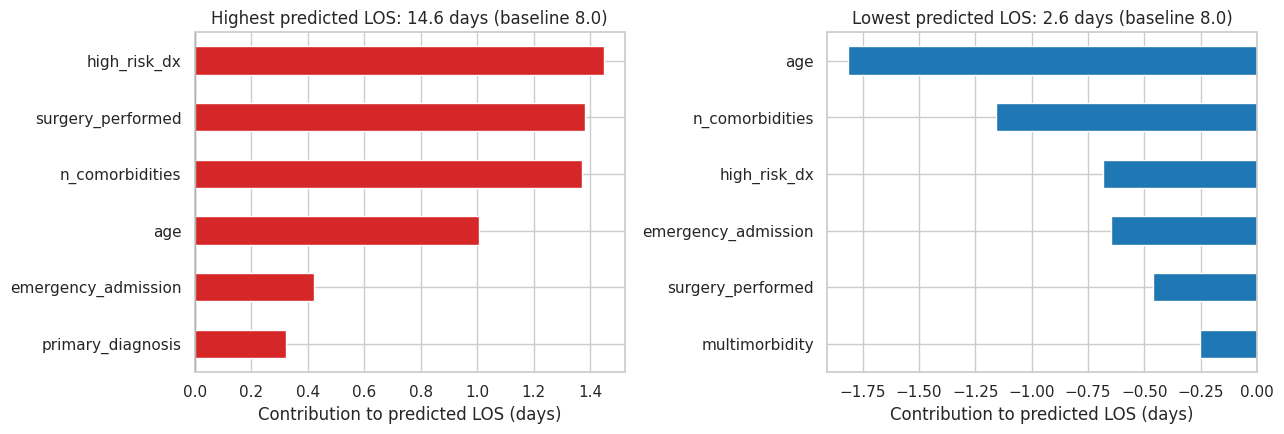

In [31]:
prep = gb_pipe.named_steps['prep']
gbm = gb_pipe.named_steps['model']
feat_names = prep.get_feature_names_out()

def orig_name(n):
    n = n.split('__', 1)[1]
    for c in categorical_cols:
        if n.startswith(c + '_'):
            return c
    return n

def explain_patient(row):
    Xp = prep.transform(row)
    if hasattr(Xp, 'toarray'):
        Xp = Xp.toarray()
    contrib = {}
    for est in gbm.estimators_[:, 0]:
        f = est.tree_.feature[0]                      # the one feature this depth-1 tree splits on
        if f < 0:
            continue
        name = orig_name(feat_names[f])
        contrib[name] = contrib.get(name, 0) + gbm.learning_rate * est.predict(Xp)[0]
    base = gbm.init_.predict(Xp)[0]
    total = base + sum(contrib.values())
    assert abs(total - gb_pipe.predict(row)[0]) < 1e-6, "breakdown does not match the model"
    return base, pd.Series(contrib).sort_values(key=abs, ascending=False)

pred_all = gb_pipe.predict(X_test_fe)
picks = {'Highest predicted LOS': int(np.argmax(pred_all)),
         'Lowest predicted LOS': int(np.argmin(pred_all))}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, pos) in zip(axes, picks.items()):
    row = X_test_fe.iloc[[pos]]
    base, contrib = explain_patient(row)
    shown = contrib.head(6)
    print(f"\n{label}: predicted {pred_all[pos]:.1f} days, actual {y_test.iloc[pos]} days")
    print(f"  baseline {base:.2f} | " + " | ".join(f"{k} {v:+.2f}" for k, v in contrib.head(6).items())
          + f" | all other features {contrib.iloc[6:].sum():+.2f}")
    print("  patient:", row[['age', 'primary_diagnosis', 'surgery_performed',
                             'emergency_admission', 'n_comorbidities']].iloc[0].to_dict())
    shown.iloc[::-1].plot.barh(ax=ax, color=['tab:red' if v > 0 else 'tab:blue' for v in shown.iloc[::-1]])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{label}: {pred_all[pos]:.1f} days (baseline {base:.1f})")
    ax.set_xlabel('Contribution to predicted LOS (days)')
plt.tight_layout(); plt.show()

The breakdown above shows how a prediction can be communicated. The patient with the highest predicted LOS (14.6 days; actual 16) is an 86-year-old with sepsis, surgery, an emergency admission, and four comorbidities, and each factor adds a visible amount. The lowest (2.6 days; actual 2) is a 20-year-old non-emergency pneumonia patient with no comorbidities. These are the extreme cases, where the model happened to do well, so they are illustrations and not typical performance. Related features split credit (diagnosis appears as both `high_risk_dx` and `primary_diagnosis`), so a clinical display should combine them into a single "diagnosis" contribution.

### Model Transparency

**How explainable are the predictions to different stakeholders?**
- **Doctors and nurses:** A per-patient breakdown like the one above, listing the top contributing factors in clinical terms (for example, "sepsis +1.5 days, surgery +1.4 days"), is easy to read and easy to sanity-check against clinical judgment. A clinician who sees a surprising prediction can see exactly which input drove it.
- **Hospital administrators:** Global feature importance (diagnosis group, age, surgery, comorbidity count, and emergency status carry the model; demographics and vitals contribute almost nothing) plus aggregate accuracy (typical error about 2.2 days; 61% of predictions within 2 days) is the level of detail they need for planning.
- **Patients:** They should not be shown a single number as a promise. A plain-language statement such as "Patients like you typically stay 6 to 11 days; your care team will update this as you recover" is more honest and useful than a point prediction or a model description.
- **Comparison with the text model:** The final structured model is exactly additive, so this explanation is exact. The fine-tuned DistilBERT (about 66 million parameters) has no exact equivalent, and approximations such as attribution methods would be harder to verify. Since the text model added no accuracy (R² 0.269 vs. 0.284), transparency is a further reason to prefer the structured model.

**What methods could make the decisions more transparent?**
Per-patient feature contributions (exact for an additive model, or SHAP for more complex ones); global importance and partial-dependence plots; a model card documenting training data, intended use, performance, subgroup results, and limitations; showing prediction ranges instead of single values; and publishing the monitoring dashboard to the clinical oversight group.

**What level of interpretability is ethically required?**
This is my view, not a regulatory standard. A tool that influences how resources are allocated, and could indirectly affect care, should be interpretable enough that (1) a clinician can see why a prediction was made and disagree with it, (2) an auditor can check that no group is systematically disadvantaged, and (3) the hospital can explain the model's role to a patient who asks. I would not accept a black-box model for this task when a simple additive model performs as well, which is what my results show.

### Communication of Limitations

**What are the key limitations to communicate to users?**
- Modest accuracy: the model explains about 28% of the variation in LOS (R² 0.28). The typical error is about 2.2 days, and 81% of predictions fall within 3 days, which is useful for planning a ward but not for deciding about an individual patient.
- Blind spot for long stays: patients who stay 15 or more days (about 5% of patients, roughly 12% of bed-days) were under-predicted by about 11 days on average. Short stays (1-4 days) were over-predicted by about 2.6 days. Predictions are pulled toward the middle.
- Only admission-time information is used, so the model cannot respond to complications or recovery during the stay.
- The data is synthetic, from one hospital over one year, with no discharge disposition and an assumption that surgery is known at admission. Performance on real patients, other hospitals, or other time periods is unknown.
- Subgroup results for small groups (Native American, Other race, Other gender, Uninsured) are too imprecise to conclude the model is fair to them.
- Notes added no reliable information beyond the structured fields after removing the ICU leak.

**How would I design disclaimers about uncertainty?**
Show a range with every prediction, for example the 10th to 90th percentile of past errors for similar patients, instead of a single number. Add short fixed text: "Planning estimate based on admission information. Not a prediction for this individual patient. Typical error is about 2 days; long stays are often under-predicted." Add a flag for patients in high-risk diagnosis groups, where long stays are more likely, saying that the model is least reliable for them. Never display the prediction in a form that could read as a discharge date.

**What processes should let users appeal or question predictions?**
- Clinicians can override or dismiss any prediction with one click and a short reason, and the overrides are logged.
- A named reviewer (for example, the clinical lead for the model) reviews override patterns monthly, because frequent overrides signal a model problem.
- Patients or families who question how predictions are used can ask the care team and escalate to the hospital's patient advocate; the hospital should be able to say that predictions do not determine care or discharge.
- Predictions are never the sole basis for discharge, bed assignment, or denying a service.

## Governance and Accountability

### Model Monitoring and Maintenance

**How would I monitor for performance drift or emerging biases after deployment?**

Baselines come from the held-out test set for the selected structured model (Gradient Boosting): MAE 2.21 days, RMSE 3.41, 61% of predictions within 2 days, 81% within 3 days. The alert thresholds below are my own proposals and should be set by the oversight committee.

| What to monitor | How | Frequency | Proposed alert |
|---|---|---|---|
| Overall accuracy | MAE and share within 2 days, on discharged patients with known actual LOS | Weekly (dashboard), monthly (review) | MAE above 2.6 days (about 20% worse than baseline) for 2 consecutive months |
| Bias (systematic over- or under-prediction) | Mean of actual minus predicted, overall and by ward | Monthly | Overall bias beyond plus or minus 0.5 days (baseline is about -0.1) |
| Long-stay blind spot | Share of 15+ day stays and the average miss on them | Monthly | Average miss above 14 days, or the share of 15+ day stays changing by more than 2 percentage points |
| Subgroup performance | MAE and bias by age group, gender, race/ethnicity, insurance, and income, with confidence intervals | Quarterly | Any group's MAE differs from the overall MAE by more than 0.5 days with a confidence interval that excludes the overall value |
| Input drift | Compare incoming patient mix with the training data: age distribution, diagnosis mix, share of surgery and emergency admissions, comorbidity counts (population stability index or simple mean shifts) | Monthly | Population stability index above 0.2 on any key input |
| Data quality | Missing values (comorbidities, alcohol use), new diagnosis categories, new or changed fields | Continuous checks, monthly report | Any unseen diagnosis category, or a rise in missing values |
| Clinician overrides | Count and reasons for overridden predictions | Monthly | Overrides on more than 20% of predictions |

Notes on these choices:
- Subgroup monitoring uses confidence intervals and, for small groups, pooled quarterly data. In my test set, small groups (about 40 to 110 patients) produced swings that were pure sampling noise (for example, the Uninsured group's apparent error disappeared once the long-stay patients were accounted for).
- The long-stay metric is separate because the model's weakest point is hidden by averages: 15+ day stays were under-predicted by about 11 days.
- Actual LOS is only known after discharge, so performance metrics lag by the length of a stay. Input drift checks are available immediately and serve as the early warning.
- Because predictions may change how patients are managed, monitoring has to account for feedback: if staff act on predictions, observed LOS can shift toward them. The oversight group should look for this, for example by checking whether errors shrink without any improvement in the model.

**Maintenance schedule**
- Monthly: metrics review by the model owner.
- Quarterly: subgroup fairness review by the oversight committee, and a check of whether the long-stay and override trends need action.
- Annually: retrain on the most recent 12 to 24 months, rerun the full evaluation (including the leakage checks), and compare against the current model before replacing it. The selected model must beat the current one on cross-validated metrics, and subgroup results must not get worse.
- Event-triggered: retrain or pause the model after any alert above, a change in the electronic record system or in coding practices, a new service line or ward, or a major event (for example, a pandemic wave) that changes the patient mix.
- A rollback plan: keep the previous model version available, and fall back to the simple baseline (ward-level average LOS) if the model is paused.

### Governance structures

I recommend a small standing oversight committee (meeting quarterly, with the authority to pause the model) with these members:
- A clinical lead (physician or senior nurse) to judge clinical plausibility and review overrides.
- A data science lead who owns the model, monitoring, and retraining.
- A bed management or operations representative who is the main user.
- A privacy and compliance officer for data use, access, and retention.
- An ethics or patient-advocate representative (ideally including a patient or community voice) who reviews subgroup results and complaints.

Supporting practices: a model card (intended use, training data, performance and subgroup results, known limitations) updated at every release; version control and an audit log of every prediction and every override; an approved-use statement that predictions are for aggregate planning and never for denying or limiting care; and a documented incident process for suspected harm, with the authority to pause the model immediately.

### Who should be accountable for decisions made using the model?

The model produces an estimate, and people make decisions, so accountability must stay with people:
- **Clinicians** remain accountable for care and discharge decisions. The model is advisory and must not be the sole basis for any clinical or discharge decision.
- **Bed management and operations leaders** are accountable for how predictions are used in staffing and bed allocation, including staying within the approved use.
- **The model owner (data science lead)** is accountable for the model's quality: monitoring, retraining, documenting limitations, and reporting problems.
- **The executive sponsor (for example, the Chief Medical Officer or Chief Operating Officer)** is ultimately accountable for approving deployment, funding monitoring, and acting on the committee's findings.
- **The oversight committee** is accountable for reviewing performance and fairness and for the decision to continue, change, or stop using the model.

A prediction error should never be attributed to the model alone, since the model is not a decision-maker. The hospital should be able to name who approved the model's use, who reviewed its performance last quarter, and who acted on an alert.